In [1]:
import re
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

print(plt.get_backend())

inline


In [3]:
from pathlib import Path

sql_folder = Path(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\My Project")

for sql_file in sorted(sql_folder.glob("*.sql")):
    sql_code = sql_file.read_text(encoding="utf-8")

    print(f"\nReading: {sql_file.name}")
    print(sql_code[:200])  # Preview first 200 characters

In [4]:
import pandas as pd
from pathlib import Path

data_folder = Path(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\Raw data")

sales = pd.read_csv(data_folder / "sales_transaction.csv")
customers = pd.read_csv(data_folder / "customer_profiles.csv")
products = pd.read_csv(data_folder / "product_inventory.csv")

print("Sales:", sales.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Sales: (5002, 6)
Customers: (1000, 5)
Products: (200, 5)


In [5]:
import pandas as pd
from pathlib import Path

data_folder = Path(
    r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\Raw data"
)

sales = pd.read_csv(data_folder / "sales_transaction.csv")

# Parse dates using the format in your uploaded file
sales["TransactionDate"] = pd.to_datetime(
    sales["TransactionDate"],
    format="%d/%m/%y",
    errors="coerce"
)

print("Total rows:", len(sales))
print("Date range:", sales["TransactionDate"].min(), "to",
      sales["TransactionDate"].max())

Total rows: 5002
Date range: 2023-01-01 00:00:00 to 2023-07-28 00:00:00


In [6]:
pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [7]:
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Pratham@123",
    database="project"
)

if conn.is_connected():
    print("Connected to MySQL successfully!")

Connected to MySQL successfully!


In [8]:
cursor = conn.cursor()

cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table[0])

cursor.close()

clean_customers
clean_products
clean_sales
customer_profiles
customer_rfm
product_inventory
product_perf
sales_transaction


True

In [9]:
clean_customers=pd.read_csv(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\output\tables\clean_customers.csv")

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Folder containing your exported SQL results
OUTPUT_DIR = Path(
    r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\outputs\tables"
)

# Check that the folder exists
print("Folder exists:", OUTPUT_DIR.exists())

# List all exported CSV files
csv_files = sorted(OUTPUT_DIR.glob("*.csv"))

print(f"\nTotal CSV files found: {len(csv_files)}")

for file in csv_files:
    print(file.name)

Folder exists: False

Total CSV files found: 0


In [11]:
import os
import glob

In [12]:
from pathlib import Path
import pandas as pd

folder = Path(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\output")

dfs = {f.name: pd.read_csv(f) for f in folder.glob("*.csv")}

for name, df in dfs.items():
    print(f"\n--- {name} ---")
    print(df.head())

In [13]:
from pathlib import Path

output_folder = Path(
    r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\output\tables"
)

print("Folder exists:", output_folder.exists())

if output_folder.exists():
    print("\nFiles in the folder:")
    for file in output_folder.iterdir():
        print(file.name)

Folder exists: True

Files in the folder:
abc_summary.csv
avg_order_value.csv
bottom10_products.csv
category_performance.csv
cleaned_table_counts.csv
cleaning_validation.csv
clean_customers.csv
clean_products.csv
clean_sales.csv
corrected_price_transactions.csv
customer profiles.csv
customers_never_purchased.csv
customer_months_active.csv
dq_price_consistency_rest.csv
dq_price_mismatch_detail.csv
duplicate_customers.csv
duplicate_products.csv
duplicate_transactions.csv
eda_daily_revenue.csv
eda_impact_of_price_correction.csv
eda_monthly_trend.csv
eda_overview.csv
eda_revenue_by_category.csv
eda_weekday.csv
inter_purchase_gap_raw.csv
inventory_flag_summary.csv
overstock_list.csv
price_mismatch_summary.csv
product_inventory.csv
product_performance_full.csv
purchase_frequency_distribution.csv
raw_table_counts.csv
repeat_purchase_rate.csv
revenue_correction_impact.csv
rfm_customers.csv
sales_transaction.csv
segment_by_agegroup.csv
segment_by_gender.csv
segment_by_location.csv
segment_categ

In [14]:
import pandas as pd
from pathlib import Path

output_folder = Path(
    r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\output\tables"
)

# Load the updated SQL tables
clean_sales = pd.read_csv(output_folder / "clean_sales.csv")
clean_products = pd.read_csv(output_folder / "clean_products.csv")

# Verify the data
print("Clean sales rows:", len(clean_sales))
print("Clean products rows:", len(clean_products))

display(
    clean_sales.loc[
        clean_sales["ProductID"] == 51,
        [
            "TransactionID",
            "ProductID",
            "RecordedPrice",
            "UnitPrice",
            "PriceCorrected",
            "Revenue"
        ]
    ].head(10)
)

Clean sales rows: 5000
Clean products rows: 200


,TransactionID,ProductID,RecordedPrice,UnitPrice,PriceCorrected,Revenue
87,88,51,9312.0,93.12,1,186.24
235,236,51,9312.0,93.12,1,186.24
590,591,51,9312.0,93.12,1,186.24
1376,1377,51,9312.0,93.12,1,372.48
1909,1910,51,9312.0,93.12,1,279.36
2607,2608,51,9312.0,93.12,1,93.12
2938,2939,51,9312.0,93.12,1,186.24
3376,3377,51,9312.0,93.12,1,279.36
3634,3635,51,9312.0,93.12,1,372.48
3838,3839,51,9312.0,93.12,1,279.36


In [15]:

import re
from pathlib import Path
import pandas as pd

# Folder paths
SQL_DIR = Path(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\SQL")
OUTPUT_DIR = Path(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Recognize named queries and setup blocks
MARKER = re.compile(
    r"^-- (name: \S+|setup)[ \t]*$",
    re.MULTILINE
)

def run_sql_file(conn, sql_file):

    sql_text = sql_file.read_text(encoding="utf-8")

    # Separate the file into named blocks
    parts = MARKER.split(sql_text)

    for marker, body in zip(parts[1::2], parts[2::2]):

        body = body.strip()

        if not body:
            continue

        # Execute setup statements, such as CREATE VIEW
        if marker == "setup":

            statements = [
                stmt.strip()
                for stmt in body.split(";")
                if stmt.strip()
            ]

            cursor = conn.cursor()

            try:
                for statement in statements:
                    cursor.execute(statement)

                conn.commit()
                print(f"Setup completed: {sql_file.name}")

            finally:
                cursor.close()

        # Execute a named query and export its results
        else:
            query_name = marker.split(":", 1)[1].strip()
            query = body.rstrip(";").strip()

            try:
                df = pd.read_sql_query(query, conn)

                output_file = OUTPUT_DIR / f"{query_name}.csv"
                df.to_csv(output_file, index=False)

                print(
                    f"Exported {query_name}: "
                    f"{len(df)} rows -> {output_file}"
                )

            except Exception as e:
                print(
                    f"ERROR in {sql_file.name}, "
                    f"query '{query_name}': {e}"
                )
                raise


# Process files in numerical order
for sql_file in sorted(SQL_DIR.glob("0*.sql")):
    print(f"\nProcessing {sql_file.name}")
    run_sql_file(conn, sql_file)

print("\nAll SQL files processed.")



All SQL files processed.


In [16]:

import mysql.connector

try:
    connection = mysql.connector.connect(
        host="localhost",
        user="root",
        password="Pratham@123",
        database="project"
    )

    if connection.is_connected():
        print("MySQL connection successful!")

        cursor = connection.cursor()
        cursor.execute("SELECT DATABASE()")
        print("Connected database:", cursor.fetchone()[0])

        cursor.close()
        connection.close()

except mysql.connector.Error as error:
    print("MySQL connection failed:", error)


MySQL connection successful!
Connected database: project


In [17]:
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Pratham@123",
    database="project"
)

cursor = connection.cursor()
cursor.execute("SHOW TABLES LIKE 'clean_sales'")
print(cursor.fetchall())

cursor.close()
connection.close()

[('clean_sales',)]


In [18]:

import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="Pratham@123",
    database="project"
)

cursor = connection.cursor()

print("Connection open:", connection.is_connected())

cursor.execute("SELECT DATABASE()")
print("Database:", cursor.fetchone())

cursor.execute("SHOW TABLES")
print("Tables:", cursor.fetchall())

cursor.close()
connection.close()
print("Connection test passed.")


Connection open: True
Database: ('project',)
Tables: [('clean_customers',), ('clean_products',), ('clean_sales',), ('customer_profiles',), ('customer_rfm',), ('product_inventory',), ('product_perf',), ('sales_transaction',)]
Connection test passed.


In [19]:
import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="Pratham@123",
    database="project"
)

print("Connected:", connection.is_connected())

Connected: True


In [20]:

def run_sql_file(connection, file_path):
    text = file_path.read_text(encoding="utf-8")
    parts = MARKER.split(text)

    exported = 0

    cursor = connection.cursor()

    try:
        for marker, body in zip(parts[1::2], parts[2::2]):
            body = body.strip()

            if not body:
                continue

            if marker == "setup":
                execute_setup(cursor, body)
                connection.commit()
                print(f"Setup executed: {file_path.name}")
                continue

            query_name = marker.split(":", 1)[1].strip()
            query = body.rstrip(";").strip()

            cursor.execute(query)

            if cursor.description is None:
                print(f"Skipped (no result set): {query_name}")
                continue

            columns = [column[0] for column in cursor.description]
            rows = cursor.fetchall()

            df = pd.DataFrame(rows, columns=columns)
            output_file = OUTPUT_DIR / f"{query_name}.csv"
            df.to_csv(output_file, index=False)

            exported += 1
            print(f"Exported {query_name}.csv ({len(df)} rows)")

    finally:
        cursor.close()

    return exported


In [21]:
import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="Pratham@123",
    database="project"
)

try:
    cursor = connection.cursor()

    for table in ["clean_sales", "clean_customers", "clean_products"]:
        cursor.execute(f"SHOW TABLES LIKE '{table}'")
        exists = cursor.fetchone() is not None

        if exists:
            cursor.execute(f"SELECT COUNT(*) FROM `{table}`")
            count = cursor.fetchone()[0]
            print(f"{table}: exists, {count} rows")
        else:
            print(f"{table}: MISSING")

    cursor.close()
finally:
    connection.close()

clean_sales: exists, 5000 rows
clean_customers: exists, 1000 rows
clean_products: exists, 200 rows


In [22]:

import pandas as pd
from pathlib import Path

# Your project output folder
output_folder = Path(
    r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\SQL project\Retail sql project\output\tables"
)

# Load important SQL analysis results
eda_overview = pd.read_csv(
    output_folder / "eda_overview.csv"
)

category_performance = pd.read_csv(
    output_folder / "category_performance.csv"
)

monthly_trend = pd.read_csv(
    output_folder / "eda_monthly_trend.csv"
)

top_products = pd.read_csv(
    output_folder / "top10_products.csv"
)

abc_summary = pd.read_csv(
    output_folder / "abc_summary.csv"
)

# Verify that all files loaded correctly
print("All selected files loaded successfully!")

print("\nEDA Overview:")
display(eda_overview.head())

print("\nCategory Performance:")
display(category_performance.head())

print("\nMonthly Revenue Trend:")
display(monthly_trend.head())

print("\nTop 10 Products:")
display(top_products.head())

print("\nABC Analysis Summary:")
display(abc_summary.head())


All selected files loaded successfully!

EDA Overview:


,transactions,units_sold,total_revenue,avg_revenue_per_transaction,avg_units_per_transaction,purchasing_customers,total_customers,products_sold,first_date,last_date
0,5000,12325,702003.62,140.4,2.47,989,1000,200,01/01/23,31/05/23



Category Performance:


,Category,products,units,revenue,avg_price,avg_units_per_product,avg_revenue_per_product,high_tier_products,low_tier_products,stock_units
0,Home & Kitchen,58,3477,217755.94,62.14,59.9,3754.41,16,14,16808
1,Electronics,47,3037,177548.48,59.61,64.6,3777.63,13,7,12634
2,Clothing,45,2810,162874.21,57.71,62.4,3619.43,14,12,11194
3,Beauty & Health,50,3001,143824.99,47.93,60.0,2876.50,7,17,11200



Monthly Revenue Trend:


,month,complete_days,transactions,units,revenue,revenue_per_day,active_customers
0,2001-01,1,24,58,3176.74,3176.74,24
1,2001-02,1,24,63,3428.48,3428.48,24
2,2001-03,1,24,61,2490.50,2490.50,24
3,2001-04,1,24,60,3730.02,3730.02,24
4,2001-05,1,24,48,3311.30,3311.30,24



Top 10 Products:


,RevenueRank,ProductName,Category,Price,Units,Revenue,StockLevel,InventoryFlag
0,1,Product_17,Beauty & Health,94.50,100,9450.00,208,Balanced
1,2,Product_87,Clothing,84.97,92,7817.24,145,Balanced
2,3,Product_179,Clothing,85.91,86,7388.26,380,Balanced
3,4,Product_96,Home & Kitchen,99.06,72,7132.32,252,Balanced
4,5,Product_54,Electronics,82.01,86,7052.86,352,Balanced



ABC Analysis Summary:


,ABCClass,products,pct_of_products,revenue,pct_of_revenue
0,A,118,59.0,564303.17,80.4
1,B,47,23.5,103399.42,14.7
2,C,35,17.5,34301.03,4.9


In [23]:
print("========== OVERALL BUSINESS SUMMARY ==========")
display(eda_overview)

print("\n========== CATEGORY PERFORMANCE ==========")
display(category_performance)

print("\n========== MONTHLY SALES TREND ==========")
display(monthly_trend)

print("\n========== TOP 10 PRODUCTS ==========")
display(top_products)

print("\n========== ABC ANALYSIS ==========")
display(abc_summary)

========== OVERALL BUSINESS SUMMARY ==========


,transactions,units_sold,total_revenue,avg_revenue_per_transaction,avg_units_per_transaction,purchasing_customers,total_customers,products_sold,first_date,last_date
0,5000,12325,702003.62,140.4,2.47,989,1000,200,01/01/23,31/05/23



========== CATEGORY PERFORMANCE ==========


,Category,products,units,revenue,avg_price,avg_units_per_product,avg_revenue_per_product,high_tier_products,low_tier_products,stock_units
0,Home & Kitchen,58,3477,217755.94,62.14,59.9,3754.41,16,14,16808
1,Electronics,47,3037,177548.48,59.61,64.6,3777.63,13,7,12634
2,Clothing,45,2810,162874.21,57.71,62.4,3619.43,14,12,11194
3,Beauty & Health,50,3001,143824.99,47.93,60.0,2876.50,7,17,11200



========== MONTHLY SALES TREND ==========


,month,complete_days,transactions,units,revenue,revenue_per_day,active_customers
0,2001-01,1,24,58,3176.74,3176.74,24
1,2001-02,1,24,63,3428.48,3428.48,24
2,2001-03,1,24,61,2490.50,2490.50,24
3,2001-04,1,24,60,3730.02,3730.02,24
4,2001-05,1,24,48,3311.30,3311.30,24
...,...,...,...,...,...,...,...
204,2030-05,1,24,58,3528.65,3528.65,23
205,2030-06,1,24,67,3908.77,3908.77,24
206,2031-01,1,24,68,4089.90,4089.90,24
207,2031-03,1,24,55,3468.15,3468.15,23



========== TOP 10 PRODUCTS ==========


,RevenueRank,ProductName,Category,Price,Units,Revenue,StockLevel,InventoryFlag
0,1,Product_17,Beauty & Health,94.50,100,9450.00,208,Balanced
1,2,Product_87,Clothing,84.97,92,7817.24,145,Balanced
2,3,Product_179,Clothing,85.91,86,7388.26,380,Balanced
3,4,Product_96,Home & Kitchen,99.06,72,7132.32,252,Balanced
4,5,Product_54,Electronics,82.01,86,7052.86,352,Balanced
5,6,Product_187,Beauty & Health,84.34,82,6915.88,35,Balanced
6,7,Product_156,Clothing,89.84,76,6827.84,134,Balanced
7,8,Product_57,Home & Kitchen,84.90,78,6622.20,397,Balanced
8,9,Product_200,Clothing,93.91,69,6479.79,163,Balanced
9,10,Product_127,Electronics,94.35,68,6415.80,49,Balanced



========== ABC ANALYSIS ==========


,ABCClass,products,pct_of_products,revenue,pct_of_revenue
0,A,118,59.0,564303.17,80.4
1,B,47,23.5,103399.42,14.7
2,C,35,17.5,34301.03,4.9


In [24]:
datasets = {
    "Sales": sales,
    "Customers": customers,
    "Products": products
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name.upper()} DATASET")
    print("=" * 50)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nFirst 5 rows:")
    display(df.head())


SALES DATASET
Shape: (5002, 6)

Columns:
['TransactionID', 'CustomerID', 'ProductID', 'QuantityPurchased', 'TransactionDate', 'Price']

Missing values:
TransactionID        0
CustomerID           0
ProductID            0
QuantityPurchased    0
TransactionDate      0
Price                0
dtype: int64

First 5 rows:


,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,Price
0,1,103,120,3,2023-01-01,30.43
1,2,436,126,1,2023-01-01,15.19
2,3,861,55,3,2023-01-01,67.76
3,4,271,27,2,2023-01-01,65.77
4,5,107,118,1,2023-01-01,14.55



CUSTOMERS DATASET
Shape: (1000, 5)

Columns:
['CustomerID', 'Age', 'Gender', 'Location', 'JoinDate']

Missing values:
CustomerID     0
Age            0
Gender         0
Location      13
JoinDate       0
dtype: int64

First 5 rows:


,CustomerID,Age,Gender,Location,JoinDate
0,1,63,Other,East,01/01/20
1,2,63,Male,North,02/01/20
2,3,34,Other,North,03/01/20
3,4,19,Other,NaN,04/01/20
4,5,57,Male,North,05/01/20



PRODUCTS DATASET
Shape: (200, 5)

Columns:
['ProductID', 'ProductName', 'Category', 'StockLevel', 'Price']

Missing values:
ProductID      0
ProductName    0
Category       0
StockLevel     0
Price          0
dtype: int64

First 5 rows:


,ProductID,ProductName,Category,StockLevel,Price
0,1,Product_1,Clothing,22,46.11
1,2,Product_2,Home & Kitchen,140,81.60
2,3,Product_3,Home & Kitchen,473,78.72
3,4,Product_4,Clothing,386,22.06
4,5,Product_5,Beauty & Health,284,17.97


## 1.1 Check data types, missing values, and duplicates

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Apply a consistent visualization style
sns.set_theme(style="whitegrid", context="notebook")

datasets = {
    "Sales": sales,
    "Customers": customers,
    "Products": products
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"{name.upper()} DATASET")
    print("=" * 60)

    print("Rows and columns:", df.shape)

    print("\nColumn data types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nFirst 5 rows:")
    display(df.head())


SALES DATASET
Rows and columns: (5002, 6)

Column data types:
TransactionID                 int64
CustomerID                    int64
ProductID                     int64
QuantityPurchased             int64
TransactionDate      datetime64[ns]
Price                       float64
dtype: object

Missing values:
TransactionID        0
CustomerID           0
ProductID            0
QuantityPurchased    0
TransactionDate      0
Price                0
dtype: int64

Duplicate rows: 2

First 5 rows:


,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,Price
0,1,103,120,3,2023-01-01,30.43
1,2,436,126,1,2023-01-01,15.19
2,3,861,55,3,2023-01-01,67.76
3,4,271,27,2,2023-01-01,65.77
4,5,107,118,1,2023-01-01,14.55



CUSTOMERS DATASET
Rows and columns: (1000, 5)

Column data types:
CustomerID     int64
Age            int64
Gender        object
Location      object
JoinDate      object
dtype: object

Missing values:
CustomerID     0
Age            0
Gender         0
Location      13
JoinDate       0
dtype: int64

Duplicate rows: 0

First 5 rows:


,CustomerID,Age,Gender,Location,JoinDate
0,1,63,Other,East,01/01/20
1,2,63,Male,North,02/01/20
2,3,34,Other,North,03/01/20
3,4,19,Other,NaN,04/01/20
4,5,57,Male,North,05/01/20



PRODUCTS DATASET
Rows and columns: (200, 5)

Column data types:
ProductID        int64
ProductName     object
Category        object
StockLevel       int64
Price          float64
dtype: object

Missing values:
ProductID      0
ProductName    0
Category       0
StockLevel     0
Price          0
dtype: int64

Duplicate rows: 0

First 5 rows:


,ProductID,ProductName,Category,StockLevel,Price
0,1,Product_1,Clothing,22,46.11
1,2,Product_2,Home & Kitchen,140,81.60
2,3,Product_3,Home & Kitchen,473,78.72
3,4,Product_4,Clothing,386,22.06
4,5,Product_5,Beauty & Health,284,17.97


In [26]:
print("SALES COLUMNS:")
print(sales.columns.tolist())

print("\nCUSTOMER COLUMNS:")
print(customers.columns.tolist())

print("\nPRODUCT COLUMNS:")
print(products.columns.tolist())

SALES COLUMNS:
['TransactionID', 'CustomerID', 'ProductID', 'QuantityPurchased', 'TransactionDate', 'Price']

CUSTOMER COLUMNS:
['CustomerID', 'Age', 'Gender', 'Location', 'JoinDate']

PRODUCT COLUMNS:
['ProductID', 'ProductName', 'Category', 'StockLevel', 'Price']


In [27]:
display(sales.head(10))

print("\nDate column candidates:")
print([col for col in sales.columns if "date" in col.lower()])

print("\nPrice-related columns:")
print([col for col in sales.columns if "price" in col.lower()])

print("\nQuantity-related columns:")
print([col for col in sales.columns if "quantity" in col.lower()])

,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,Price
0,1,103,120,3,2023-01-01,30.43
1,2,436,126,1,2023-01-01,15.19
2,3,861,55,3,2023-01-01,67.76
3,4,271,27,2,2023-01-01,65.77
4,5,107,118,1,2023-01-01,14.55
5,6,72,53,1,2023-01-01,26.27
6,7,701,39,2,2023-01-01,95.92
7,8,21,65,4,2023-01-01,17.19
8,9,615,145,4,2023-01-01,66.00
9,10,122,158,2,2023-01-01,22.27



Date column candidates:
['TransactionDate']

Price-related columns:
['Price']

Quantity-related columns:
['QuantityPurchased']


In [28]:
# Check missing values in Location
print("Missing Location values:", customers["Location"].isnull().sum())

# Display customers whose locations are missing
display(customers[customers["Location"].isnull()])

Missing Location values: 13


,CustomerID,Age,Gender,Location,JoinDate
3,4,19,Other,NaN,04/01/20
112,113,21,Male,NaN,02/05/20
114,115,43,Female,NaN,05/05/20
218,219,23,Male,NaN,27/08/20
238,239,40,Other,NaN,18/09/20
321,322,35,Female,NaN,18/12/20
378,379,27,Female,NaN,18/02/21
404,405,26,Female,NaN,19/03/21
447,448,44,Female,NaN,05/05/21
475,476,45,Female,NaN,05/06/21


In [29]:
missing_percentage = (
    customers["Location"].isnull().sum()
    / len(customers)
) * 100

print(f"Missing Location Percentage: {missing_percentage:.2f}%")

Missing Location Percentage: 1.30%


In [30]:
# Handle missing locations
customers["Location"] = customers["Location"].fillna("Unknown")

# Verify
print("Remaining missing values:", customers["Location"].isnull().sum())
print("Total customer records:", len(customers))

Remaining missing values: 0
Total customer records: 1000


In [31]:
for name, df in {
    "Sales": sales,
    "Products": products
}.items():

    print(f"\n{name} — Missing values:")
    print(df.isnull().sum())


Sales — Missing values:
TransactionID        0
CustomerID           0
ProductID            0
QuantityPurchased    0
TransactionDate      0
Price                0
dtype: int64

Products — Missing values:
ProductID      0
ProductName    0
Category       0
StockLevel     0
Price          0
dtype: int64


In [32]:
# Check the dimensions of each dataset

print("SALES DATA")
print("Rows:", sales.shape[0])
print("Columns:", sales.shape[1])

print("\nCUSTOMERS DATA")
print("Rows:", customers.shape[0])
print("Columns:", customers.shape[1])

print("\nPRODUCTS DATA")
print("Rows:", products.shape[0])
print("Columns:", products.shape[1])

SALES DATA
Rows: 5002
Columns: 6

CUSTOMERS DATA
Rows: 1000
Columns: 5

PRODUCTS DATA
Rows: 200
Columns: 5


In [33]:
# Check duplicate rows in each dataset

datasets = {
    "Sales": sales,
    "Customers": customers,
    "Products": products
}

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Sales: 2 duplicate rows
Customers: 0 duplicate rows
Products: 0 duplicate rows


In [34]:
for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(f"{name.upper()} DATASET")
    print("=" * 40)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 rows:")
    display(df.head())


SALES DATASET

Column names:
['TransactionID', 'CustomerID', 'ProductID', 'QuantityPurchased', 'TransactionDate', 'Price']

Data types:
TransactionID                 int64
CustomerID                    int64
ProductID                     int64
QuantityPurchased             int64
TransactionDate      datetime64[ns]
Price                       float64
dtype: object

First 5 rows:


,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,Price
0,1,103,120,3,2023-01-01,30.43
1,2,436,126,1,2023-01-01,15.19
2,3,861,55,3,2023-01-01,67.76
3,4,271,27,2,2023-01-01,65.77
4,5,107,118,1,2023-01-01,14.55



CUSTOMERS DATASET

Column names:
['CustomerID', 'Age', 'Gender', 'Location', 'JoinDate']

Data types:
CustomerID     int64
Age            int64
Gender        object
Location      object
JoinDate      object
dtype: object

First 5 rows:


,CustomerID,Age,Gender,Location,JoinDate
0,1,63,Other,East,01/01/20
1,2,63,Male,North,02/01/20
2,3,34,Other,North,03/01/20
3,4,19,Other,Unknown,04/01/20
4,5,57,Male,North,05/01/20



PRODUCTS DATASET

Column names:
['ProductID', 'ProductName', 'Category', 'StockLevel', 'Price']

Data types:
ProductID        int64
ProductName     object
Category        object
StockLevel       int64
Price          float64
dtype: object

First 5 rows:


,ProductID,ProductName,Category,StockLevel,Price
0,1,Product_1,Clothing,22,46.11
1,2,Product_2,Home & Kitchen,140,81.60
2,3,Product_3,Home & Kitchen,473,78.72
3,4,Product_4,Clothing,386,22.06
4,5,Product_5,Beauty & Health,284,17.97


In [35]:
# Display completely duplicated sales records

duplicate_sales = sales[sales.duplicated(keep=False)]

print("Number of rows involved in duplicates:", len(duplicate_sales))

display(
    duplicate_sales.sort_values(
        by=["TransactionID", "CustomerID"]
    )
)


Number of rows involved in duplicates: 4


,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,Price
4998,4999,904,188,2,2023-07-28,36.22
5000,4999,904,188,2,2023-07-28,36.22
4999,5000,215,159,2,2023-07-28,17.42
5001,5000,215,159,2,2023-07-28,17.42


In [36]:
# Convert dates into proper datetime format

sales["TransactionDate"] = pd.to_datetime(
    sales["TransactionDate"],
    format="%d/%m/%y",
    errors="coerce"
)

customers["JoinDate"] = pd.to_datetime(
    customers["JoinDate"],
    format="%d/%m/%y",
    errors="coerce"
)

# Verify the conversion

print("Sales date type:", sales["TransactionDate"].dtype)
print("Customer join date type:", customers["JoinDate"].dtype)

print(
    "Invalid sales dates:",
    sales["TransactionDate"].isna().sum()
)

print(
    "Invalid customer join dates:",
    customers["JoinDate"].isna().sum()
)

Sales date type: datetime64[ns]
Customer join date type: datetime64[ns]
Invalid sales dates: 0
Invalid customer join dates: 0


In [37]:
print("========== SALES VALIDATION ==========")

print("Quantity <= 0:", (sales["QuantityPurchased"] <= 0).sum())
print("Price <= 0:", (sales["Price"] <= 0).sum())

print("\n========== CUSTOMER VALIDATION ==========")

print("Age <= 0:", (customers["Age"] <= 0).sum())
print("Age > 100:", (customers["Age"] > 100).sum())

print("\n========== PRODUCT VALIDATION ==========")

print("StockLevel < 0:", (products["StockLevel"] < 0).sum())
print("Price <= 0:", (products["Price"] <= 0).sum())

========== SALES VALIDATION ==========
Quantity <= 0: 0
Price <= 0: 0

========== CUSTOMER VALIDATION ==========
Age <= 0: 0
Age > 100: 1

========== PRODUCT VALIDATION ==========
StockLevel < 0: 0
Price <= 0: 0


In [38]:
# Remove exact duplicate rows from sales

rows_before = len(sales)

sales = sales.drop_duplicates().copy()

rows_after = len(sales)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Duplicate rows remaining:", sales.duplicated().sum())
print("Rows removed:", rows_before - rows_after)

Rows before: 5002
Rows after: 5000
Duplicate rows remaining: 0
Rows removed: 2


In [39]:
# Find customers whose age exceeds 100

display(
    customers.loc[
        customers["Age"] > 100,
        ["CustomerID", "Age", "Gender", "Location", "JoinDate"]
    ]
)

,CustomerID,Age,Gender,Location,JoinDate
667,668,131,Male,Unknown,2022-01-01


# Python EDA

In [40]:

# ==========================================
# STEP 1: OVERALL BUSINESS PERFORMANCE
# ==========================================

# Calculate revenue for each sales record
sales["Revenue"] = sales["QuantityPurchased"] * sales["Price"]

# Calculate key performance indicators
total_revenue = sales["Revenue"].sum()

total_units_sold = sales["QuantityPurchased"].sum()

total_transactions = sales["TransactionID"].nunique()

unique_customers = sales["CustomerID"].nunique()

average_transaction_value = (
    total_revenue / total_transactions
    if total_transactions > 0 else 0
)

average_quantity_per_transaction = (
    total_units_sold / total_transactions
    if total_transactions > 0 else 0
)

# Display results
print("=" * 45)
print("RETAIL BUSINESS PERFORMANCE")
print("=" * 45)

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Unique Purchasing Customers: {unique_customers:,}")
print(f"Average Transaction Value: ₹{average_transaction_value:,.2f}")
print(f"Average Quantity per Transaction: {average_quantity_per_transaction:.2f}")

RETAIL BUSINESS PERFORMANCE
Total Revenue: ₹1,209,042.02
Total Units Sold: 12,325
Total Transactions: 5,000
Unique Purchasing Customers: 989
Average Transaction Value: ₹241.81
Average Quantity per Transaction: 2.46


## Analyze Revenue by Product Category

In [41]:

# ==========================================
# STEP 2: REVENUE BY PRODUCT CATEGORY
# ==========================================

# Merge sales with product details
sales_product = sales.merge(
    products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)

# Calculate revenue by category
category_revenue = (
    sales_product
    .groupby("Category", as_index=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("QuantityPurchased", "sum"),
        Transaction_Count=("TransactionID", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

display(category_revenue)

,Category,Total_Revenue,Total_Units_Sold,Transaction_Count,Unique_Customers
1,Clothing,669912.61,2810,1135,665
3,Home & Kitchen,217755.94,3477,1431,756
2,Electronics,177548.48,3037,1199,694
0,Beauty & Health,143824.99,3001,1235,724


### Revenue per category bar chart 

In [42]:

# ==========================================
# STEP 3: MONTHLY REVENUE TREND
# ==========================================

# Ensure the transaction date is in datetime format
sales["TransactionDate"] = pd.to_datetime(
    sales["TransactionDate"],
    errors="coerce"
)

# Remove rows with invalid dates for this analysis only
valid_date_sales = sales.dropna(subset=["TransactionDate"]).copy()

# Create a month column
valid_date_sales["Month"] = (
    valid_date_sales["TransactionDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Aggregate monthly performance
monthly_revenue = (
    valid_date_sales
    .groupby("Month", as_index=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("QuantityPurchased", "sum"),
        Transaction_Count=("TransactionID", "nunique")
    )
    .sort_values("Month")
)

display(monthly_revenue)

,Month,Total_Revenue,Total_Units_Sold,Transaction_Count
0,2023-01-01,159602.46,1797,744
1,2023-02-01,133566.51,1737,672
2,2023-03-01,130928.13,1812,744
3,2023-04-01,110779.97,1790,720
4,2023-05-01,149093.24,1796,744
5,2023-06-01,323463.40,1784,720
6,2023-07-01,201608.31,1609,656


### Montly Reveue trend

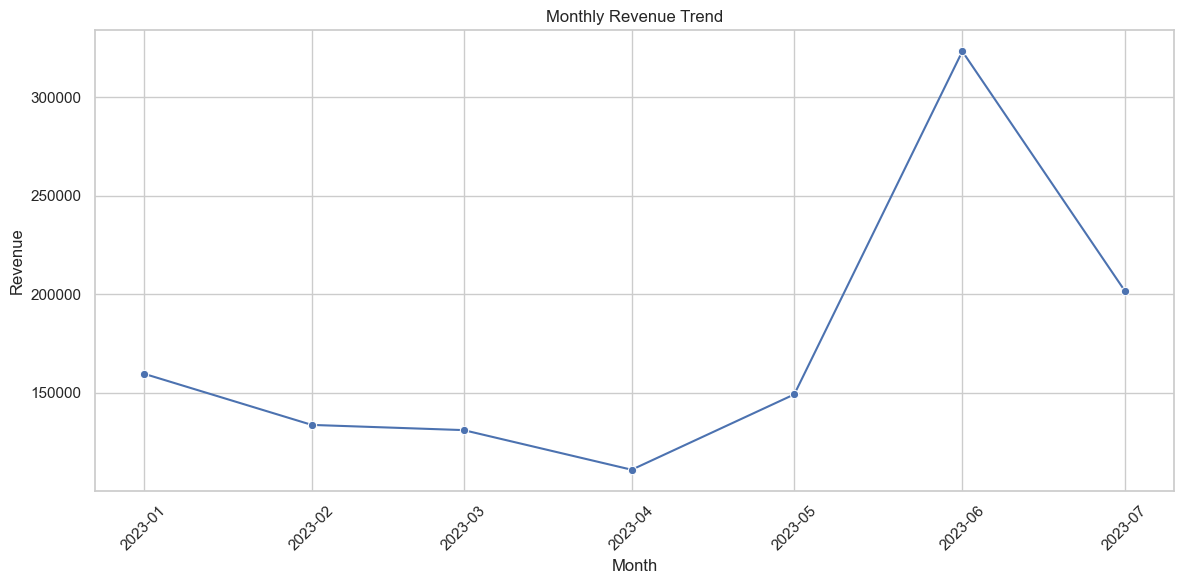

In [43]:

# Line chart: Monthly revenue

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Total_Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Top 10 Best-Selling Products

### Calculate product-level performance

In [44]:

# ==========================================
# STEP 4: PRODUCT PERFORMANCE ANALYSIS
# ==========================================

# Merge sales with product information
sales_product = sales.merge(
    products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)

# Calculate product-level metrics
product_performance = (
    sales_product
    .groupby(["ProductID", "ProductName", "Category"], as_index=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("QuantityPurchased", "sum"),
        Total_Transactions=("TransactionID", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Display the top 10 products
top_10_products = product_performance.head(10)

display(top_10_products)


,ProductID,ProductName,Category,Total_Revenue,Total_Units_Sold,Total_Transactions,Unique_Customers
50,51,Product_51,Clothing,512160.00,55,20,19
16,17,Product_17,Beauty & Health,9450.00,100,39,39
86,87,Product_87,Clothing,7817.24,92,35,35
178,179,Product_179,Clothing,7388.26,86,31,30
95,96,Product_96,Home & Kitchen,7132.32,72,28,28
53,54,Product_54,Electronics,7052.86,86,32,31
186,187,Product_187,Beauty & Health,6915.88,82,34,33
155,156,Product_156,Clothing,6827.84,76,33,32
56,57,Product_57,Home & Kitchen,6622.20,78,33,32
199,200,Product_200,Clothing,6479.79,69,24,24


In [45]:
# Check Product 51 in the currently loaded cleaned sales data

display(
    clean_sales.loc[
        clean_sales["ProductID"] == 51,
        [
            "TransactionID",
            "RecordedPrice",
            "UnitPrice",
            "PriceCorrected",
            "Revenue"
        ]
    ].head(10)
)

print("\nTotal revenue in clean_sales:", clean_sales["Revenue"].sum())

,TransactionID,RecordedPrice,UnitPrice,PriceCorrected,Revenue
87,88,9312.0,93.12,1,186.24
235,236,9312.0,93.12,1,186.24
590,591,9312.0,93.12,1,186.24
1376,1377,9312.0,93.12,1,372.48
1909,1910,9312.0,93.12,1,279.36
2607,2608,9312.0,93.12,1,93.12
2938,2939,9312.0,93.12,1,186.24
3376,3377,9312.0,93.12,1,279.36
3634,3635,9312.0,93.12,1,372.48
3838,3839,9312.0,93.12,1,279.36



Total revenue in clean_sales: 702003.62


In [46]:
clean_sales.head()

,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,RecordedPrice,UnitPrice,PriceCorrected,RawRevenue,Revenue
0,1,103,120,3,01/01/23,30.43,30.43,0,91.29,91.29
1,2,436,126,1,01/01/23,15.19,15.19,0,15.19,15.19
2,3,861,55,3,01/01/23,67.76,67.76,0,203.28,203.28
3,4,271,27,2,01/01/23,65.77,65.77,0,131.54,131.54
4,5,107,118,1,01/01/23,14.55,14.55,0,14.55,14.55


In [47]:
clean_products.head()

,ProductID,ProductName,Category,StockLevel,CatalogPrice
0,1,Product_1,Clothing,22,46.11
1,2,Product_2,Home & Kitchen,140,81.60
2,3,Product_3,Home & Kitchen,473,78.72
3,4,Product_4,Clothing,386,22.06
4,5,Product_5,Beauty & Health,284,17.97


In [48]:
# ==========================================
# REBUILD PRODUCT PERFORMANCE FROM SQL DATA
# ==========================================

# Ensure Revenue is numeric
clean_sales["Revenue"] = pd.to_numeric(
    clean_sales["Revenue"],
    errors="coerce"
)

# Merge cleaned sales with product information
sales_product = clean_sales.merge(
    clean_products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)



,ProductID,ProductName,Category,Total_Revenue,Total_Units_Sold,Total_Transactions,Unique_Customers
0,17,Product_17,Beauty & Health,9450.00,100,39,39
1,87,Product_87,Clothing,7817.24,92,35,35
2,179,Product_179,Clothing,7388.26,86,31,30
3,96,Product_96,Home & Kitchen,7132.32,72,28,28
4,54,Product_54,Electronics,7052.86,86,32,31
5,187,Product_187,Beauty & Health,6915.88,82,34,33
6,156,Product_156,Clothing,6827.84,76,33,32
7,57,Product_57,Home & Kitchen,6622.20,78,33,32
8,200,Product_200,Clothing,6479.79,69,24,24
9,127,Product_127,Electronics,6415.80,68,29,29


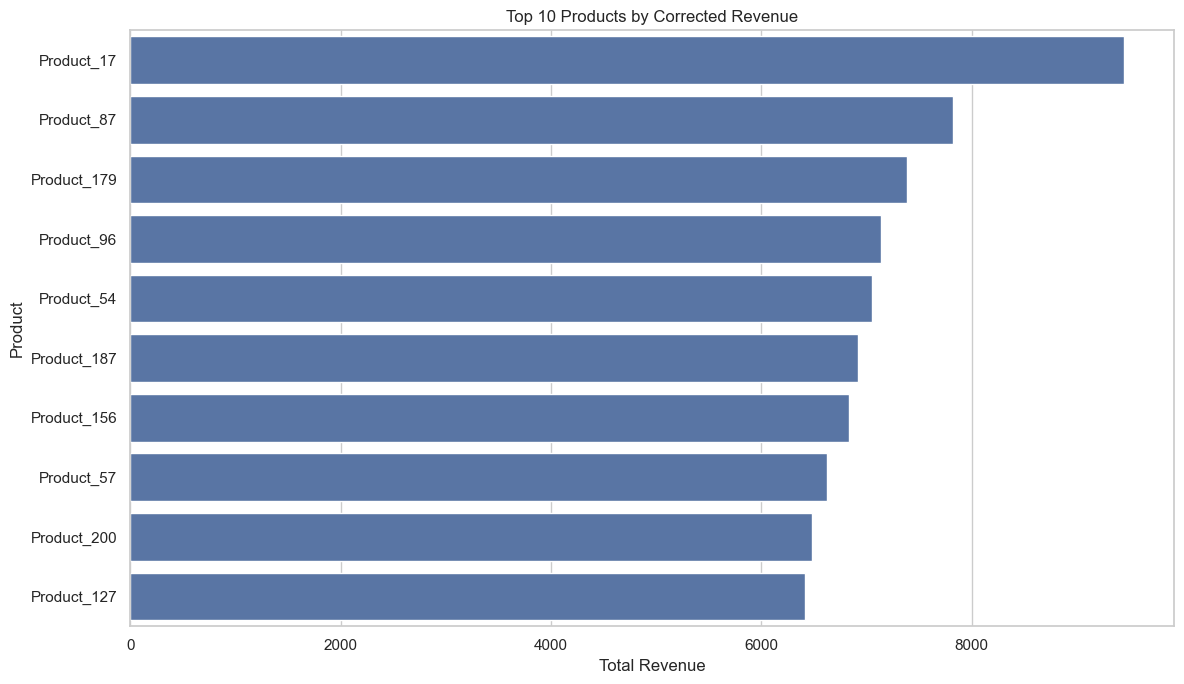

In [49]:
# Recalculate product performance using SQL Revenue
product_performance = (
    sales_product
    .groupby(
        ["ProductID", "ProductName", "Category"],
        as_index=False
    )
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("QuantityPurchased", "sum"),
        Total_Transactions=("TransactionID", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
    .reset_index(drop=True)
)

top_10_products = product_performance.head(10).copy()

display(top_10_products.round(2))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_products,
    x="Total_Revenue",
    y="ProductName"
)

plt.title("Top 10 Products by Corrected Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [50]:
# Show the current top 10 products and their revenue

display(
    top_10_products[
        ["ProductName", "Total_Revenue", "Total_Units_Sold"]
    ].round(2)
)

,ProductName,Total_Revenue,Total_Units_Sold
0,Product_17,9450.00,100
1,Product_87,7817.24,92
2,Product_179,7388.26,86
3,Product_96,7132.32,72
4,Product_54,7052.86,86
5,Product_187,6915.88,82
6,Product_156,6827.84,76
7,Product_57,6622.20,78
8,Product_200,6479.79,69
9,Product_127,6415.80,68


### TOP 10 PRODUCTS BY QUANTITY SOLD

,ProductID,ProductName,Category,Total_Revenue,Total_Units_Sold,Total_Transactions,Unique_Customers
108,182,Product_182,Electronics,3144.66,102,38,37
0,17,Product_17,Beauty & Health,9450.00,100,39,39
1,87,Product_87,Clothing,7817.24,92,35,35
55,71,Product_71,Electronics,4729.12,88,31,31
13,195,Product_195,Home & Kitchen,6229.20,87,32,32
2,179,Product_179,Clothing,7388.26,86,31,30
94,177,Product_177,Clothing,3354.00,86,30,30
4,54,Product_54,Electronics,7052.86,86,32,31
145,22,Product_22,Beauty & Health,1978.80,85,35,35
164,13,Product_13,Electronics,1596.30,85,34,33


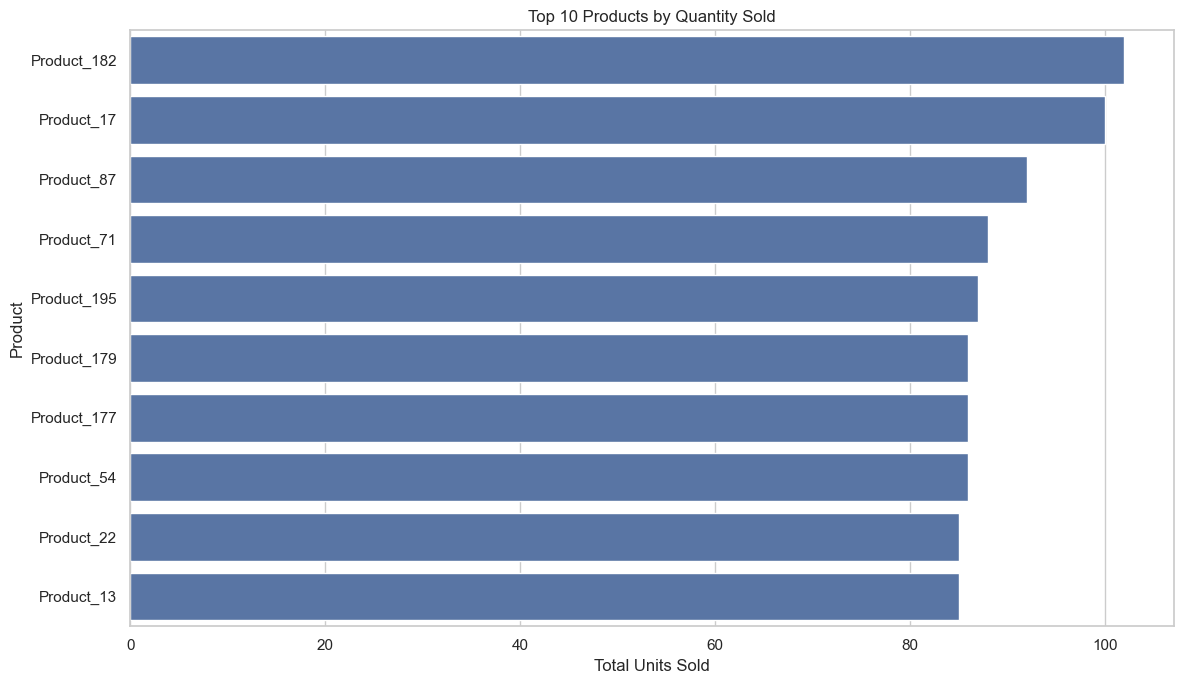

In [51]:

# ==========================================
# TOP 10 PRODUCTS BY QUANTITY SOLD
# ==========================================

top_10_quantity = (
    product_performance
    .sort_values("Total_Units_Sold", ascending=False)
    .head(10)
)

display(top_10_quantity)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_quantity,
    x="Total_Units_Sold",
    y="ProductName"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [52]:
# Display the top 10 products with exact revenue values

display(
    top_10_products[
        [
            "ProductID",
            "ProductName",
            "Category",
            "Total_Revenue",
            "Total_Units_Sold",
            "Total_Transactions"
        ]
    ].round(2)
)

,ProductID,ProductName,Category,Total_Revenue,Total_Units_Sold,Total_Transactions
0,17,Product_17,Beauty & Health,9450.00,100,39
1,87,Product_87,Clothing,7817.24,92,35
2,179,Product_179,Clothing,7388.26,86,31
3,96,Product_96,Home & Kitchen,7132.32,72,28
4,54,Product_54,Electronics,7052.86,86,32
5,187,Product_187,Beauty & Health,6915.88,82,34
6,156,Product_156,Clothing,6827.84,76,33
7,57,Product_57,Home & Kitchen,6622.20,78,33
8,200,Product_200,Clothing,6479.79,69,24
9,127,Product_127,Electronics,6415.80,68,29


In [53]:
# Summary statistics for product revenue

print(product_performance["Total_Revenue"].describe())

print(
    "\nTotal revenue:",
    round(product_performance["Total_Revenue"].sum(), 2)
)

print(
    "Product_51 revenue:",
    round(
        product_performance.loc[
            product_performance["ProductName"] == "Product_51",
            "Total_Revenue"
        ].sum(),
        2
    )
)

count     200.000000
mean     3510.018100
std      1872.208224
min       484.100000
25%      1909.915000
50%      3289.425000
75%      4998.712500
max      9450.000000
Name: Total_Revenue, dtype: float64

Total revenue: 702003.62
Product_51 revenue: 5121.6


In [54]:
# Inspect individual sales records for Product_51

product_51_sales = sales_product[
    sales_product["ProductName"] == "Product_51"
].copy()

display(
    product_51_sales.sort_values(
        "Revenue",
        ascending=False
    ).head(10)
)

,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,RecordedPrice,UnitPrice,PriceCorrected,RawRevenue,Revenue,ProductName,Category
1376,1377,172,51,4,27/02/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
4157,4158,930,51,4,23/06/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
3634,3635,534,51,4,01/06/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
3958,3959,984,51,4,14/06/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
4407,4408,819,51,4,03/07/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
4753,4754,821,51,4,18/07/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
3961,3962,371,51,4,15/06/23,9312.0,93.12,1,37248.0,372.48,Product_51,Clothing
3838,3839,973,51,3,09/06/23,9312.0,93.12,1,27936.0,279.36,Product_51,Clothing
4967,4968,973,51,3,26/07/23,9312.0,93.12,1,27936.0,279.36,Product_51,Clothing
4220,4221,893,51,3,25/06/23,9312.0,93.12,1,27936.0,279.36,Product_51,Clothing


In [55]:
# Check Product_51 in the product inventory

display(
    products[products["ProductID"] == 51]
)

,ProductID,ProductName,Category,StockLevel,Price
50,51,Product_51,Clothing,199,93.12


In [56]:
# Compare sales prices with inventory prices for all products

price_check = sales.merge(
    products[["ProductID", "Price"]],
    on="ProductID",
    how="left",
    suffixes=("_Sales", "_Inventory"),
    validate="many_to_one"
)

price_check["Price_Ratio"] = (
    price_check["Price_Sales"] / price_check["Price_Inventory"]
)

# Summarize unusual price ratios
print("Price ratio distribution:")
display(price_check["Price_Ratio"].describe())

print("\nMost common price ratios:")
display(
    price_check["Price_Ratio"]
    .round(4)
    .value_counts()
    .head(15)
)

Price ratio distribution:


count    5000.0000
mean        1.3960
std         6.2494
min         1.0000
25%         1.0000
50%         1.0000
75%         1.0000
max       100.0000
Name: Price_Ratio, dtype: float64


Most common price ratios:


Price_Ratio
1.0      4980
100.0      20
Name: count, dtype: int64

In [57]:
# Identify products with a 100x price mismatch

affected_sales = price_check[
    np.isclose(price_check["Price_Ratio"], 100.0)
]

affected_products = (
    affected_sales
    .groupby("ProductID", as_index=False)
    .agg(
        Affected_Transactions=("TransactionID", "nunique"),
        Sales_Price=("Price_Sales", "first"),
        Inventory_Price=("Price_Inventory", "first")
    )
)

affected_products["Price_Difference"] = (
    affected_products["Sales_Price"]
    - affected_products["Inventory_Price"]
)

display(affected_products)

,ProductID,Affected_Transactions,Sales_Price,Inventory_Price,Price_Difference
0,51,20,9312.0,93.12,9218.88


In [58]:

# ==========================================
# CORRECT SALES PRICE INCONSISTENCIES
# ==========================================

# Keep the original sales data unchanged
sales_corrected = sales.copy()

# Map each ProductID to its inventory price
inventory_prices = products.set_index("ProductID")["Price"]

# Get the corresponding inventory price for every sale
sales_corrected["InventoryPrice"] = (
    sales_corrected["ProductID"].map(inventory_prices)
)

# Identify transactions where sales price is 100x inventory price
price_mismatch_mask = np.isclose(
    sales_corrected["Price"],
    sales_corrected["InventoryPrice"] * 100,
    rtol=1e-5,
    atol=0.01
)

# Count affected records
print("Records requiring correction:", price_mismatch_mask.sum())

# Correct only the affected prices
sales_corrected.loc[price_mismatch_mask, "Price"] = (
    sales_corrected.loc[price_mismatch_mask, "InventoryPrice"]
)

# Calculate revenue using corrected prices
sales_corrected["Revenue"] = (
    sales_corrected["QuantityPurchased"]
    * sales_corrected["Price"]
)

# Verify results
print(
    "Remaining 100x mismatches:",
    np.isclose(
        sales_corrected["Price"],
        sales_corrected["InventoryPrice"] * 100,
        rtol=1e-5,
        atol=0.01
    ).sum()
)

print("Corrected total revenue:", round(sales_corrected["Revenue"].sum(), 2))

# Remove the helper column
sales_corrected.drop(columns=["InventoryPrice"], inplace=True)


Records requiring correction: 20
Remaining 100x mismatches: 0
Corrected total revenue: 702003.62


In [59]:

# Recalculate product performance using corrected sales

sales_product = sales_corrected.merge(
    products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)

product_performance = (
    sales_product
    .groupby(
        ["ProductID", "ProductName", "Category"],
        as_index=False
    )
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("QuantityPurchased", "sum"),
        Total_Transactions=("TransactionID", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

top_10_products = product_performance.head(10)

display(top_10_products.round(2))


,ProductID,ProductName,Category,Total_Revenue,Total_Units_Sold,Total_Transactions,Unique_Customers
16,17,Product_17,Beauty & Health,9450.00,100,39,39
86,87,Product_87,Clothing,7817.24,92,35,35
178,179,Product_179,Clothing,7388.26,86,31,30
95,96,Product_96,Home & Kitchen,7132.32,72,28,28
53,54,Product_54,Electronics,7052.86,86,32,31
186,187,Product_187,Beauty & Health,6915.88,82,34,33
155,156,Product_156,Clothing,6827.84,76,33,32
56,57,Product_57,Home & Kitchen,6622.20,78,33,32
199,200,Product_200,Clothing,6479.79,69,24,24
126,127,Product_127,Electronics,6415.80,68,29,29


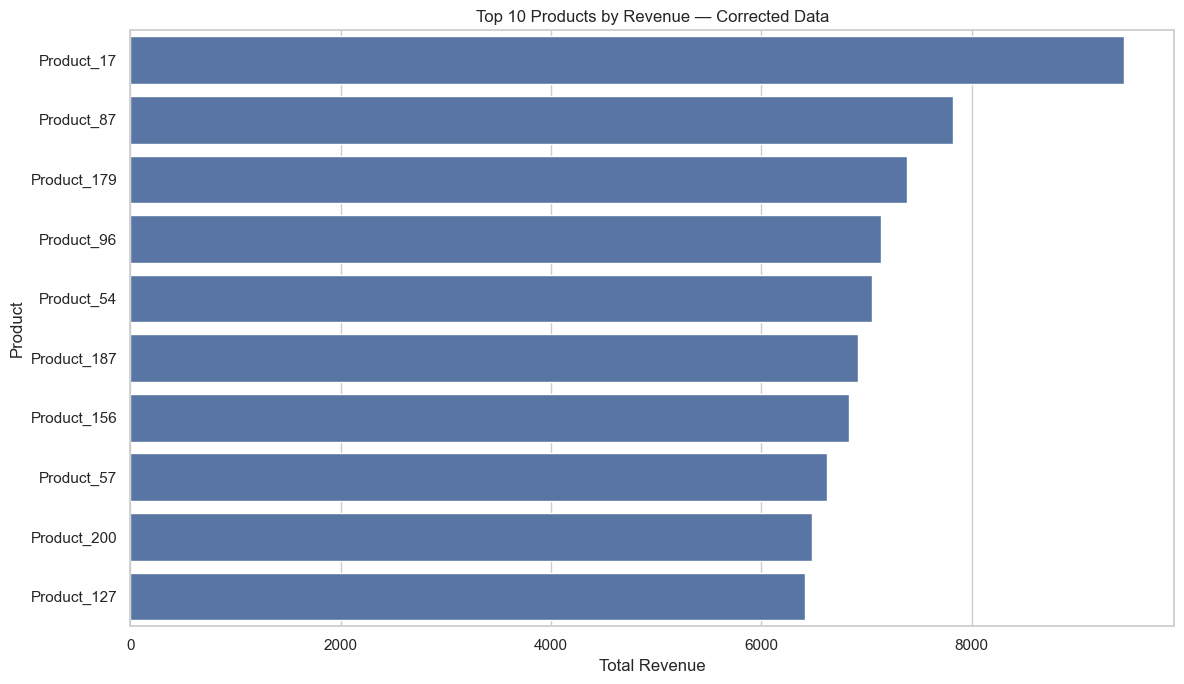

In [60]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_products,
    x="Total_Revenue",
    y="ProductName"
)

plt.title("Top 10 Products by Revenue — Corrected Data")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


## Revenue Contribution by Product Category

,Category,Total_Revenue,Revenue_Percentage
3,Home & Kitchen,217755.94,31.02
2,Electronics,177548.48,25.29
1,Clothing,162874.21,23.20
0,Beauty & Health,143824.99,20.49


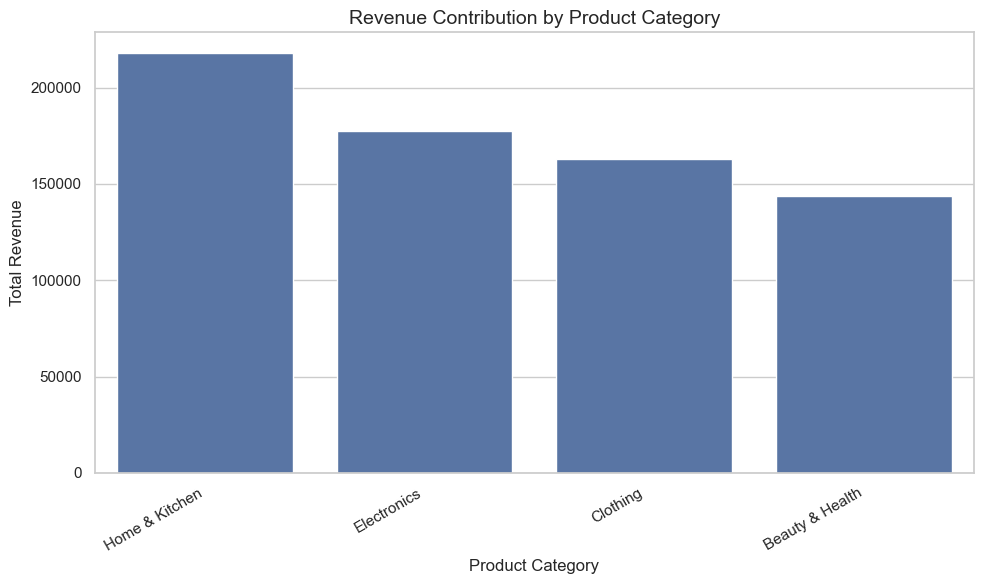

In [61]:

# ==========================================
# REVENUE CONTRIBUTION BY PRODUCT CATEGORY
# ==========================================

# Calculate revenue by category using corrected sales data
category_revenue = (
    sales_product
    .groupby("Category", as_index=False)
    .agg(Total_Revenue=("Revenue", "sum"))
    .sort_values("Total_Revenue", ascending=False)
)

# Calculate percentage contribution
total_revenue = category_revenue["Total_Revenue"].sum()

category_revenue["Revenue_Percentage"] = (
    category_revenue["Total_Revenue"] / total_revenue * 100
)

display(category_revenue.round(2))

# Plot the results
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=category_revenue,
    x="Category",
    y="Total_Revenue"
)

plt.title("Revenue Contribution by Product Category", fontsize=14)
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


In [62]:
# ==========================================
# COMPARE REVENUE BY CATEGORY
# RAW DATA VS CORRECTED SQL DATA
# ==========================================

# 1. Revenue from original raw sales
raw_sales_check = sales.merge(
    products[["ProductID", "Category"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)

raw_sales_check["Raw_Revenue"] = (
    raw_sales_check["QuantityPurchased"]
    * raw_sales_check["Price"]
)

raw_category_revenue = (
    raw_sales_check
    .groupby("Category")["Raw_Revenue"]
    .sum()
    .rename("Raw_Revenue")
)

# 2. Revenue from corrected SQL sales
clean_category_revenue = (
    sales_product
    .groupby("Category")["Revenue"]
    .sum()
    .rename("Corrected_SQL_Revenue")
)

# 3. Compare the two results
category_comparison = pd.concat(
    [raw_category_revenue, clean_category_revenue],
    axis=1
).fillna(0)

category_comparison["Difference"] = (
    category_comparison["Raw_Revenue"]
    - category_comparison["Corrected_SQL_Revenue"]
)

display(category_comparison.round(2))

,Raw_Revenue,Corrected_SQL_Revenue,Difference
Category,,,
Beauty & Health,143824.99,143824.99,0.0
Clothing,669912.61,162874.21,507038.4
Electronics,177548.48,177548.48,0.0
Home & Kitchen,217755.94,217755.94,0.0


In [63]:
# Verify corrected revenue totals

print(
    "Total corrected sales revenue:",
    round(clean_sales["Revenue"].sum(), 2)
)

print(
    "Total category revenue:",
    round(category_revenue["Total_Revenue"].sum(), 2)
)

print(
    "Revenue totals match:",
    np.isclose(
        clean_sales["Revenue"].sum(),
        category_revenue["Total_Revenue"].sum()
    )
)

Total corrected sales revenue: 702003.62
Total category revenue: 702003.62
Revenue totals match: True


In [64]:
# Check the columns in both DataFrames
print("clean_sales columns:")
print(clean_sales.columns.tolist())

print("\ncategory_revenue:")
display(category_revenue)

print("\nTotal rows in clean_sales:", len(clean_sales))
print("Total rows in category_revenue:", len(category_revenue))

print("\nTotal revenue in clean_sales:",
      round(clean_sales["Revenue"].sum(), 2))

clean_sales columns:
['TransactionID', 'CustomerID', 'ProductID', 'QuantityPurchased', 'TransactionDate', 'RecordedPrice', 'UnitPrice', 'PriceCorrected', 'RawRevenue', 'Revenue']

category_revenue:


,Category,Total_Revenue,Revenue_Percentage
3,Home & Kitchen,217755.94,31.019205
2,Electronics,177548.48,25.291676
1,Clothing,162874.21,23.201335
0,Beauty & Health,143824.99,20.487785



Total rows in clean_sales: 5000
Total rows in category_revenue: 4

Total revenue in clean_sales: 702003.62


In [65]:
# TOP 10 CUSTOMERS BY CORRECTED REVENUE

top_10_customers = (
    clean_sales
    .groupby("CustomerID", as_index=False)
    .agg(Total_Revenue=("Revenue", "sum"))
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
    .sort_values("Total_Revenue", ascending=False)
)

display(top_10_customers.round(2))

,CustomerID,Total_Revenue
924,936,2834.47
657,664,2519.04
663,670,2432.15
38,39,2221.29
429,435,2158.98
946,958,2104.71
359,364,1885.40
402,407,1882.26
909,921,1866.29
72,75,1862.73


## Calculate customer-level metrics

In [66]:
# PRODUCT PERFORMANCE USING THE CLEANED SALES DATA

sales_product = clean_sales.merge(
    clean_products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left",
    validate="many_to_one"
)

product_performance = (
    sales_product
    .groupby(
        ["ProductID", "ProductName", "Category"],
        as_index=False
    )
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("QuantityPurchased", "sum"),
        Total_Transactions=("TransactionID", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

top_10_products = product_performance.head(10)

display(top_10_products.round(2))

,ProductID,ProductName,Category,Total_Revenue,Total_Units_Sold,Total_Transactions,Unique_Customers
16,17,Product_17,Beauty & Health,9450.00,100,39,39
86,87,Product_87,Clothing,7817.24,92,35,35
178,179,Product_179,Clothing,7388.26,86,31,30
95,96,Product_96,Home & Kitchen,7132.32,72,28,28
53,54,Product_54,Electronics,7052.86,86,32,31
186,187,Product_187,Beauty & Health,6915.88,82,34,33
155,156,Product_156,Clothing,6827.84,76,33,32
56,57,Product_57,Home & Kitchen,6622.20,78,33,32
199,200,Product_200,Clothing,6479.79,69,24,24
126,127,Product_127,Electronics,6415.80,68,29,29


In [67]:
# CUSTOMER PURCHASING BEHAVIOUR

customer_analysis = (
    clean_sales
    .groupby("CustomerID", as_index=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Transactions=("TransactionID", "nunique"),
        Total_Units_Purchased=("QuantityPurchased", "sum")
    )
)

# Classify customers by purchase frequency
customer_analysis["Purchase_Frequency"] = np.where(
    customer_analysis["Total_Transactions"] == 1,
    "One-time Customer",
    "Repeat Customer"
)

display(customer_analysis.head(10))

print("Total unique purchasing customers:",
      customer_analysis["CustomerID"].nunique())

print("One-time customers:",
      (customer_analysis["Purchase_Frequency"] == "One-time Customer").sum())

print("Repeat customers:",
      (customer_analysis["Purchase_Frequency"] == "Repeat Customer").sum())

,CustomerID,Total_Revenue,Total_Transactions,Total_Units_Purchased,Purchase_Frequency
0,1,1188.04,9,24,Repeat Customer
1,2,895.57,6,16,Repeat Customer
2,3,513.03,4,10,Repeat Customer
3,4,174.08,2,6,Repeat Customer
4,5,582.73,5,12,Repeat Customer
5,6,80.70,1,1,One-time Customer
6,7,1383.86,7,22,Repeat Customer
7,8,1297.25,7,23,Repeat Customer
8,9,649.93,3,9,Repeat Customer
9,10,377.90,6,12,Repeat Customer


Total unique purchasing customers: 989
One-time customers: 39
Repeat customers: 950


,Customer_Type,Customer_Count
0,Repeat Customer,950
1,One-time Customer,39


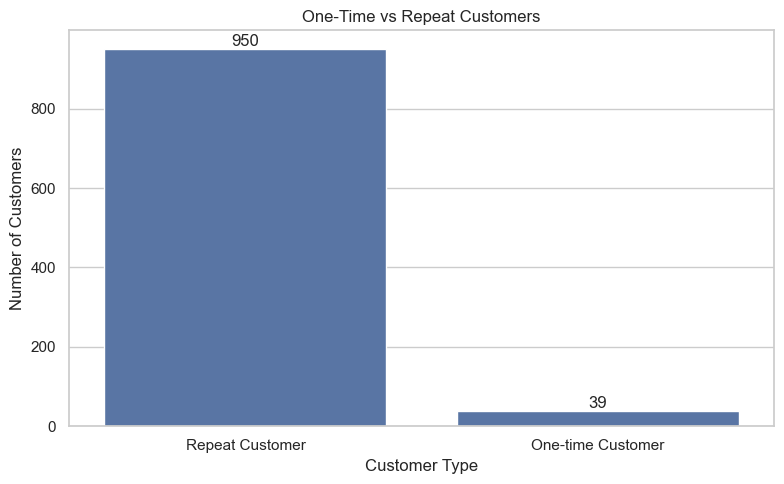

In [68]:
# CUSTOMER TYPE DISTRIBUTION

customer_type_counts = (
    customer_analysis["Purchase_Frequency"]
    .value_counts()
    .rename_axis("Customer_Type")
    .reset_index(name="Customer_Count")
)

display(customer_type_counts)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=customer_type_counts,
    x="Customer_Type",
    y="Customer_Count"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [69]:
# REVENUE CONTRIBUTION BY CUSTOMER TYPE

customer_type_revenue = (
    customer_analysis
    .groupby("Purchase_Frequency", as_index=False)
    .agg(
        Total_Revenue=("Total_Revenue", "sum"),
        Customer_Count=("CustomerID", "nunique")
    )
)

customer_type_revenue["Revenue_Per_Customer"] = (
    customer_type_revenue["Total_Revenue"] /
    customer_type_revenue["Customer_Count"]
)

display(customer_type_revenue.round(2))

,Purchase_Frequency,Total_Revenue,Customer_Count,Revenue_Per_Customer
0,One-time Customer,5458.97,39,139.97
1,Repeat Customer,696544.65,950,733.20


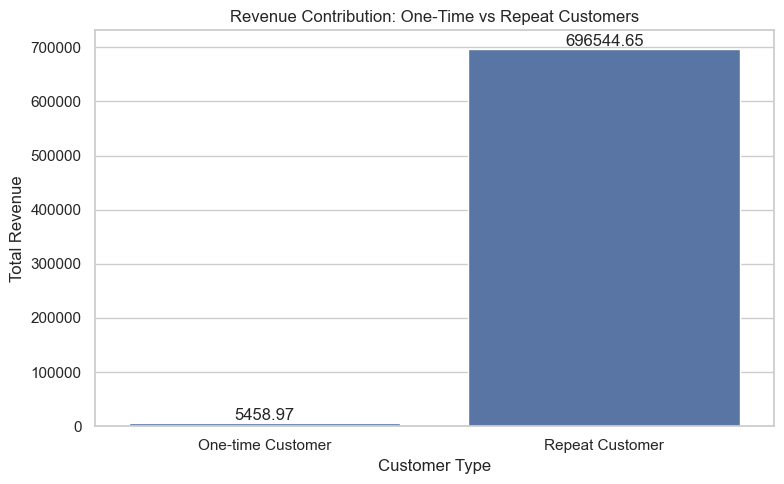

In [70]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=customer_type_revenue,
    x="Purchase_Frequency",
    y="Total_Revenue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.title("Revenue Contribution: One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

### Analyse Revenue Concentration

In [71]:
# CUSTOMER REVENUE CONCENTRATION

customer_revenue = (
    clean_sales
    .groupby("CustomerID", as_index=False)
    .agg(Total_Revenue=("Revenue", "sum"))
    .sort_values("Total_Revenue", ascending=False)
    .reset_index(drop=True)
)

customer_revenue["Cumulative_Revenue"] = (
    customer_revenue["Total_Revenue"].cumsum()
)

total_revenue = customer_revenue["Total_Revenue"].sum()

customer_revenue["Cumulative_Revenue_Percentage"] = (
    customer_revenue["Cumulative_Revenue"] / total_revenue * 100
)

customer_revenue["Cumulative_Customer_Percentage"] = (
    (np.arange(len(customer_revenue)) + 1) /
    len(customer_revenue) * 100
)

display(customer_revenue.head(10).round(2))

# Revenue contribution of the top 10% of purchasing customers
top_10_percent_count = max(
    1,
    int(np.ceil(len(customer_revenue) * 0.10))
)

top_10_percent_revenue = (
    customer_revenue.head(top_10_percent_count)["Total_Revenue"].sum()
)

print(
    "Revenue contribution of top 10% of customers:",
    round(top_10_percent_revenue / total_revenue * 100, 2),
    "%"
)

,CustomerID,Total_Revenue,Cumulative_Revenue,Cumulative_Revenue_Percentage,Cumulative_Customer_Percentage
0,936,2834.47,2834.47,0.40,0.10
1,664,2519.04,5353.51,0.76,0.20
2,670,2432.15,7785.66,1.11,0.30
3,39,2221.29,10006.95,1.43,0.40
4,435,2158.98,12165.93,1.73,0.51
5,958,2104.71,14270.64,2.03,0.61
6,364,1885.40,16156.04,2.30,0.71
7,407,1882.26,18038.30,2.57,0.81
8,921,1866.29,19904.59,2.84,0.91
9,75,1862.73,21767.32,3.10,1.01


Revenue contribution of top 10% of customers: 21.61 %


## Customer Segmentation Using RFM Analysis

In [73]:
# ==========================================
# CUSTOMER SEGMENTATION: RFM ANALYSIS
# ==========================================

# Ensure transaction dates are in datetime format
clean_sales["TransactionDate"] = pd.to_datetime(
    clean_sales["TransactionDate"],
    errors="coerce",
    dayfirst=True
)

# Remove rows without valid transaction dates for RFM calculations
rfm_sales = clean_sales.dropna(
    subset=["TransactionDate", "CustomerID", "Revenue"]
).copy()

# Set the analysis date to one day after the latest transaction
analysis_date = (
    rfm_sales["TransactionDate"].max()
    + pd.Timedelta(days=1)
)

# Calculate RFM metrics for each customer
rfm_basic = (
    rfm_sales.groupby("CustomerID")
    .agg(
        Recency=("TransactionDate",
                 lambda dates: (analysis_date - dates.max()).days),
        Frequency=("TransactionID", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

display(rfm_basic.head(10))

print("Customers included in RFM analysis:", len(rfm_basic))
print("Analysis date:", analysis_date.date())

,CustomerID,Recency,Frequency,Monetary
0,1,4,9,1188.04
1,2,85,6,895.57
2,3,88,4,513.03
3,4,134,2,174.08
4,5,150,5,582.73
5,6,154,1,80.70
6,7,15,7,1383.86
7,8,27,7,1297.25
8,9,104,3,649.93
9,10,56,6,377.90


Customers included in RFM analysis: 989
Analysis date: 2023-07-29


In [74]:
# ==========================================
# ASSIGN RFM SCORES
# ==========================================

# Recency: lower number of days = higher score
rfm_basic["R_Score"] = pd.qcut(
    rfm_basic["Recency"].rank(method="first"),
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: more transactions = higher score
rfm_basic["F_Score"] = pd.qcut(
    rfm_basic["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: higher revenue = higher score
rfm_basic["M_Score"] = pd.qcut(
    rfm_basic["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combined RFM score
rfm_basic["RFM_Score"] = (
    rfm_basic["R_Score"].astype(str)
    + rfm_basic["F_Score"].astype(str)
    + rfm_basic["M_Score"].astype(str)
)

display(rfm_basic.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,1,4,9,1188.04,4,4,4,444
1,2,85,6,895.57,1,3,3,133
2,3,88,4,513.03,1,2,2,122
3,4,134,2,174.08,1,1,1,111
4,5,150,5,582.73,1,2,2,122
5,6,154,1,80.70,1,1,1,111
6,7,15,7,1383.86,3,4,4,344
7,8,27,7,1297.25,3,4,4,344
8,9,104,3,649.93,1,1,2,112
9,10,56,6,377.90,2,3,1,231


In [75]:
# ==========================================
# CUSTOMER SEGMENTS
# ==========================================

def assign_segment(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "High-Value Customers"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 2:
        return "Loyal / Active Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "Previously Frequent Customers"

    elif row["R_Score"] >= 3 and row["F_Score"] == 1:
        return "Recent One-Time Customers"

    else:
        return "Other Customers"


rfm_basic["Customer_Segment"] = rfm_basic.apply(
    assign_segment,
    axis=1
)

display(
    rfm_basic.groupby("Customer_Segment", as_index=False)
    .agg(
        Customer_Count=("CustomerID", "nunique"),
        Total_Revenue=("Monetary", "sum"),
        Average_Revenue=("Monetary", "mean")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

,Customer_Segment,Customer_Count,Total_Revenue,Average_Revenue
0,High-Value Customers,263,290040.87,1102.82
3,Previously Frequent Customers,185,167374.36,904.73
2,Other Customers,309,131887.59,426.82
1,Loyal / Active Customers,157,87910.76,559.94
4,Recent One-Time Customers,75,24790.04,330.53


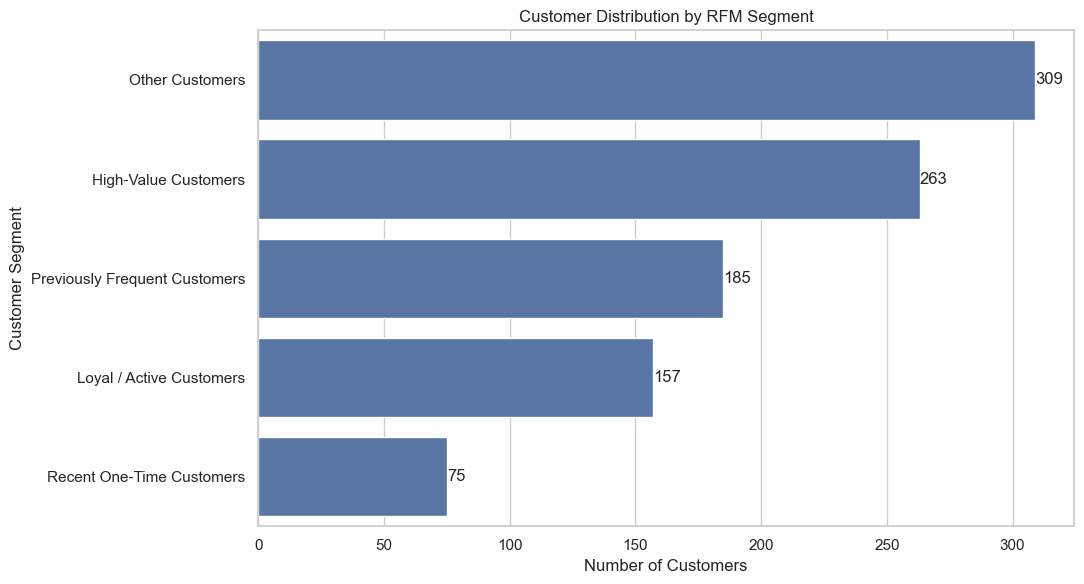

In [76]:
# ==========================================
# CUSTOMER SEGMENT DISTRIBUTION
# ==========================================

segment_summary = (
    rfm_basic["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Customer_Count")
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=segment_summary,
    x="Customer_Count",
    y="Customer_Segment"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [77]:
# ==========================================
# REVENUE ANALYSIS BY CUSTOMER SEGMENT
# ==========================================

segment_revenue = (
    rfm_basic.groupby("Customer_Segment", as_index=False)
    .agg(
        Customer_Count=("CustomerID", "nunique"),
        Total_Revenue=("Monetary", "sum"),
        Average_Revenue_Per_Customer=("Monetary", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Calculate percentage contribution to revenue
total_segment_revenue = segment_revenue["Total_Revenue"].sum()

segment_revenue["Revenue_Contribution_%"] = (
    segment_revenue["Total_Revenue"]
    / total_segment_revenue * 100
)

display(segment_revenue.round(2))

,Customer_Segment,Customer_Count,Total_Revenue,Average_Revenue_Per_Customer,Revenue_Contribution_%
0,High-Value Customers,263,290040.87,1102.82,41.32
3,Previously Frequent Customers,185,167374.36,904.73,23.84
2,Other Customers,309,131887.59,426.82,18.79
1,Loyal / Active Customers,157,87910.76,559.94,12.52
4,Recent One-Time Customers,75,24790.04,330.53,3.53


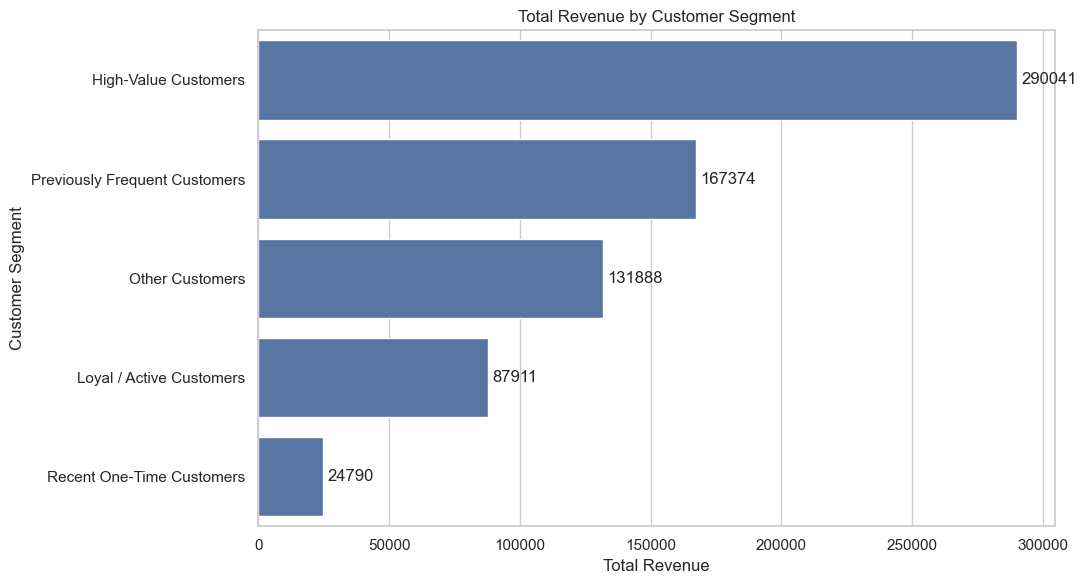

In [78]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=segment_revenue,
    x="Total_Revenue",
    y="Customer_Segment"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Total Revenue by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

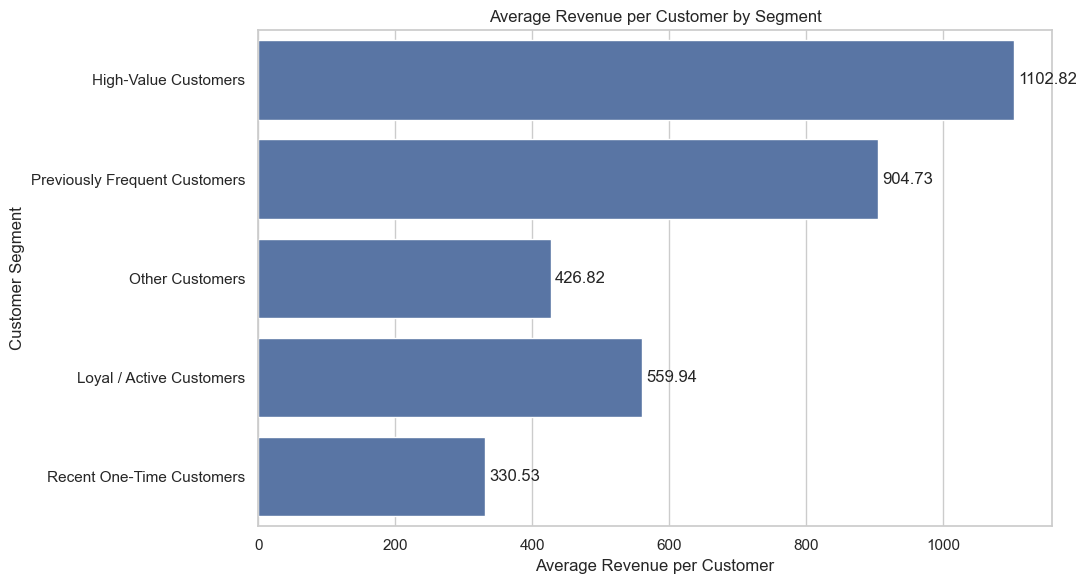

In [79]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=segment_revenue,
    x="Average_Revenue_Per_Customer",
    y="Customer_Segment"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Revenue per Customer by Segment")
plt.xlabel("Average Revenue per Customer")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [80]:
# Compare overall corrected sales revenue with RFM revenue

sales_revenue = clean_sales["Revenue"].sum()
rfm_revenue = rfm_basic["Monetary"].sum()

print("Corrected sales revenue:", round(sales_revenue, 2))
print("Revenue included in RFM:", round(rfm_revenue, 2))
print("Revenue totals match:", np.isclose(sales_revenue, rfm_revenue))

Corrected sales revenue: 702003.62
Revenue included in RFM: 702003.62
Revenue totals match: True


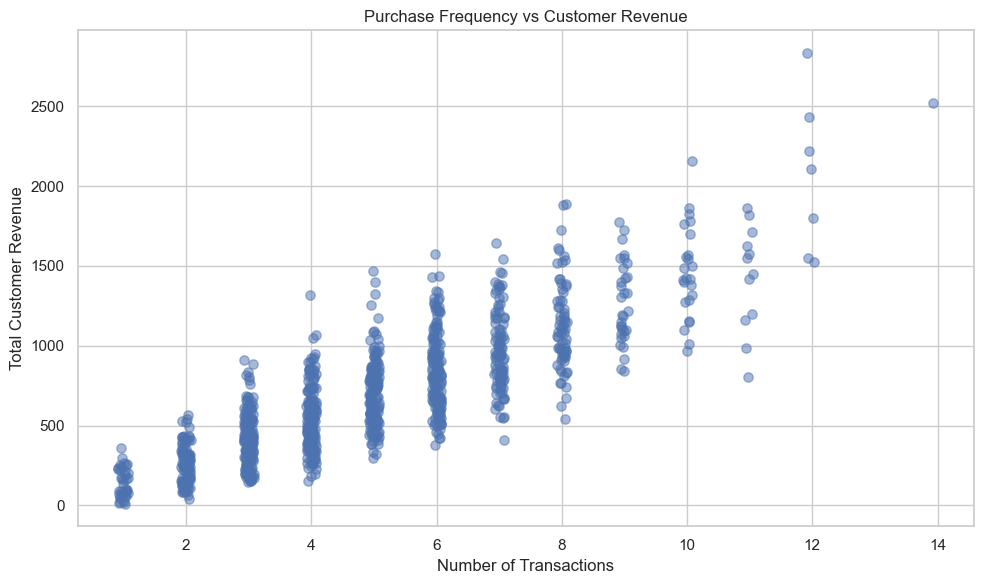

In [81]:
## Purchase Frequency vs Customer Revenue — Improved Scatter Plot

plt.figure(figsize=(10, 6))

sns.regplot(
    data=customer_analysis,
    x="Total_Transactions",
    y="Total_Revenue",
    fit_reg=False,
    x_jitter=0.08,
    scatter_kws={"alpha": 0.5, "s": 45}
)

plt.title("Purchase Frequency vs Customer Revenue")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Customer Revenue")
plt.tight_layout()
plt.show()

In [82]:
# ==========================================
# CORRELATION ANALYSIS
# ==========================================

correlation = customer_analysis[
    ["Total_Transactions", "Total_Revenue"]
].corr(method="pearson").iloc[0, 1]

print("Correlation between transactions and revenue:",
      round(correlation, 3))

Correlation between transactions and revenue: 0.838


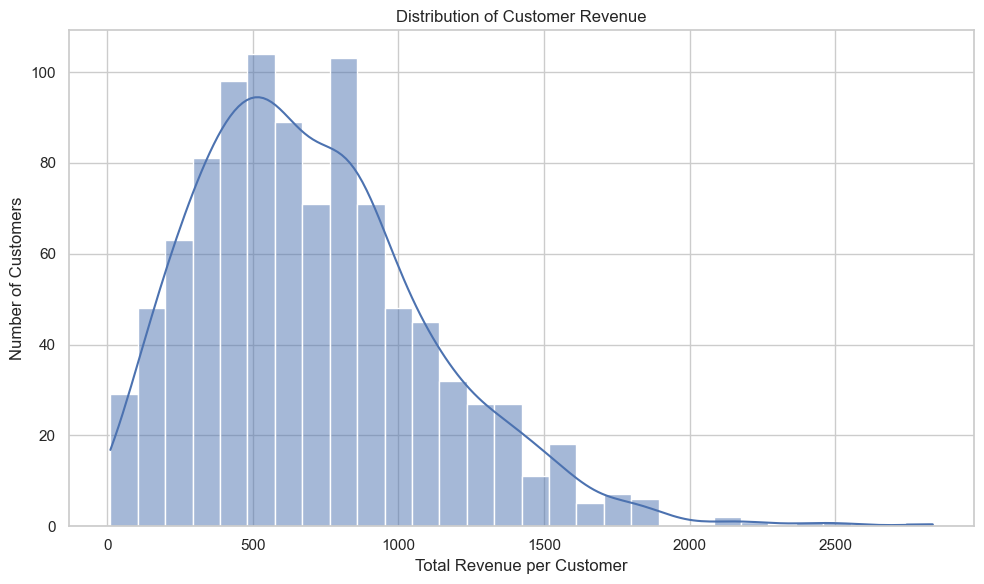

In [83]:
# ==========================================
# CUSTOMER REVENUE DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_analysis,
    x="Total_Revenue",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Revenue")
plt.xlabel("Total Revenue per Customer")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [84]:
# ==========================================
# CUSTOMER SPENDING SUMMARY
# ==========================================

customer_spending_summary = customer_analysis["Total_Revenue"].describe()

display(customer_spending_summary)

print(
    "Total Customer Revenue:",
    round(customer_analysis["Total_Revenue"].sum(), 2)
)

print(
    "Average Customer Revenue:",
    round(customer_analysis["Total_Revenue"].mean(), 2)
)

print(
    "Median Customer Revenue:",
    round(customer_analysis["Total_Revenue"].median(), 2)
)

count     989.000000
mean      709.811547
std       403.788642
min        10.950000
25%       415.910000
50%       653.380000
75%       938.330000
max      2834.470000
Name: Total_Revenue, dtype: float64

Total Customer Revenue: 702003.62
Average Customer Revenue: 709.81
Median Customer Revenue: 653.38


In [85]:
# ==========================================
# REPEAT VS ONE-TIME CUSTOMERS
# ==========================================

customer_type = customer_analysis.copy()

customer_type["Customer_Type"] = np.where(
    customer_type["Total_Transactions"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

customer_type_summary = (
    customer_type.groupby("Customer_Type")
    .agg(
        Customer_Count=("CustomerID", "nunique"),
        Total_Revenue=("Total_Revenue", "sum"),
        Average_Revenue=("Total_Revenue", "mean")
    )
    .reset_index()
)

customer_type_summary["Customer_Percentage"] = (
    customer_type_summary["Customer_Count"]
    / customer_type_summary["Customer_Count"].sum()
    * 100
).round(2)

display(customer_type_summary.round(2))

,Customer_Type,Customer_Count,Total_Revenue,Average_Revenue,Customer_Percentage
0,One-Time Customer,39,5458.97,139.97,3.94
1,Repeat Customer,950,696544.65,733.20,96.06


In [86]:
# ==========================================
# CUSTOMER REVENUE CONCENTRATION
# ==========================================

customer_revenue_ranked = customer_analysis.sort_values(
    "Total_Revenue",
    ascending=False
).copy()

total_revenue = customer_revenue_ranked["Total_Revenue"].sum()

customer_revenue_ranked["Cumulative_Revenue"] = (
    customer_revenue_ranked["Total_Revenue"].cumsum()
)

customer_revenue_ranked["Cumulative_Revenue_Percentage"] = (
    customer_revenue_ranked["Cumulative_Revenue"]
    / total_revenue
    * 100
)

customer_revenue_ranked["Customer_Rank"] = range(
    1, len(customer_revenue_ranked) + 1
)

display(customer_revenue_ranked.head(10).round(2))

,CustomerID,Total_Revenue,Total_Transactions,Total_Units_Purchased,Purchase_Frequency,Cumulative_Revenue,Cumulative_Revenue_Percentage,Customer_Rank
924,936,2834.47,12,35,Repeat Customer,2834.47,0.40,1
657,664,2519.04,14,39,Repeat Customer,5353.51,0.76,2
663,670,2432.15,12,35,Repeat Customer,7785.66,1.11,3
38,39,2221.29,12,34,Repeat Customer,10006.95,1.43,4
429,435,2158.98,10,28,Repeat Customer,12165.93,1.73,5
946,958,2104.71,12,34,Repeat Customer,14270.64,2.03,6
359,364,1885.40,8,24,Repeat Customer,16156.04,2.30,7
402,407,1882.26,8,23,Repeat Customer,18038.30,2.57,8
909,921,1866.29,10,28,Repeat Customer,19904.59,2.84,9
72,75,1862.73,11,24,Repeat Customer,21767.32,3.10,10


In [87]:
# ==========================================
# TOP 10% CUSTOMERS' REVENUE CONTRIBUTION
# ==========================================

top_10_percent_count = max(
    1,
    int(np.ceil(len(customer_revenue_ranked) * 0.10))
)

top_10_percent_customers = customer_revenue_ranked.head(
    top_10_percent_count
)

top_10_revenue = top_10_percent_customers["Total_Revenue"].sum()

top_10_revenue_percentage = (
    top_10_revenue / total_revenue * 100
)

print("Total Customers:", len(customer_revenue_ranked))
print("Top 10% Customer Count:", top_10_percent_count)
print("Revenue from Top 10% Customers:", round(top_10_revenue, 2))
print("Top 10% Revenue Contribution:", round(top_10_revenue_percentage, 2), "%")

Total Customers: 989
Top 10% Customer Count: 99
Revenue from Top 10% Customers: 151696.17
Top 10% Revenue Contribution: 21.61 %


In [88]:
sales['Revenue'] = sales['QuantityPurchased'] * sales['Price']
sales.head()

,TransactionID,CustomerID,ProductID,QuantityPurchased,TransactionDate,Price,Revenue
0,1,103,120,3,2023-01-01,30.43,91.29
1,2,436,126,1,2023-01-01,15.19,15.19
2,3,861,55,3,2023-01-01,67.76,203.28
3,4,271,27,2,2023-01-01,65.77,131.54
4,5,107,118,1,2023-01-01,14.55,14.55


,Month,Revenue
0,2023-01,159602.46
1,2023-02,133566.51
2,2023-03,130928.13
3,2023-04,110779.97
4,2023-05,149093.24
5,2023-06,323463.40
6,2023-07,201608.31


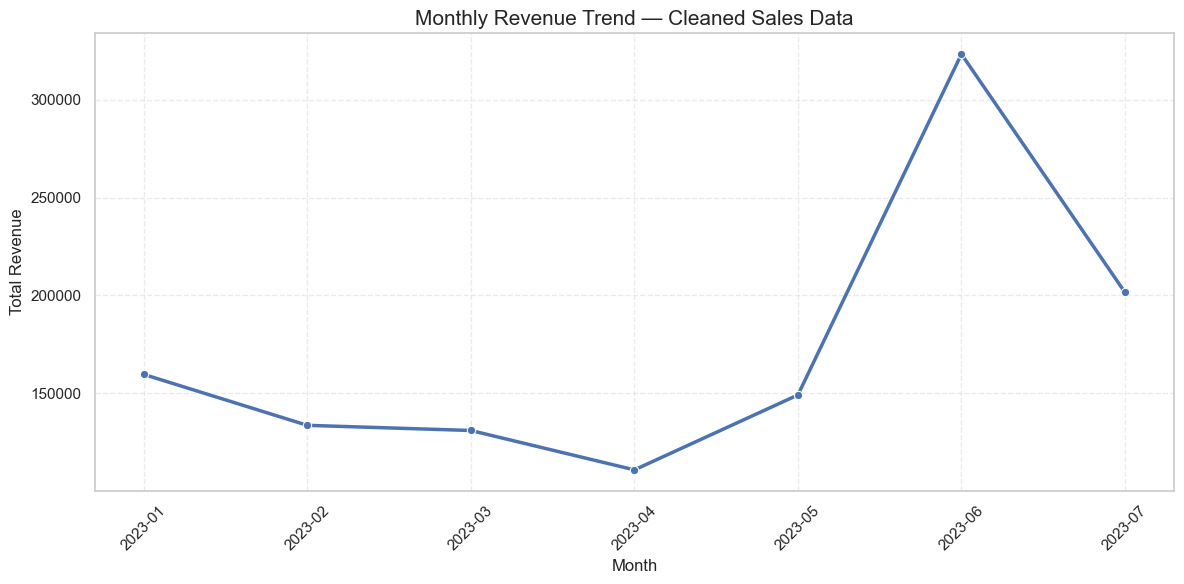

In [89]:

# ==========================================
# GRAPH 1: MONTHLY REVENUE TREND
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Work with a copy of the cleaned dataset
sales_analysis = sales.copy()

# Convert TransactionDate to datetime
sales_analysis["TransactionDate"] = pd.to_datetime(
    sales_analysis["TransactionDate"],
    errors="coerce"
)

# Ensure Revenue is numeric
sales_analysis["Revenue"] = pd.to_numeric(
    sales_analysis["Revenue"],
    errors="coerce"
)

# Calculate monthly revenue
monthly_revenue = (
    sales_analysis
    .dropna(subset=["TransactionDate", "Revenue"])
    .assign(
        Month=lambda df: df["TransactionDate"].dt.to_period("M")
    )
    .groupby("Month", as_index=False)["Revenue"]
    .sum()
    .sort_values("Month")
)

# Format month for display
monthly_revenue["Month"] = monthly_revenue["Month"].astype(str)

# Display results
display(monthly_revenue)

# Plot the monthly revenue trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Revenue Trend — Cleaned Sales Data", fontsize=15)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
plt.show()


In [90]:
display(
    clean_sales[
        ["TransactionID", "TransactionDate", "Revenue"]
    ].head(10)
)

display(clean_sales["TransactionDate"].tail(10))

,TransactionID,TransactionDate,Revenue
0,1,2023-01-01,91.29
1,2,2023-01-01,15.19
2,3,2023-01-01,203.28
3,4,2023-01-01,131.54
4,5,2023-01-01,14.55
5,6,2023-01-01,26.27
6,7,2023-01-01,191.84
7,8,2023-01-01,68.76
8,9,2023-01-01,264.00
9,10,2023-01-01,44.54


4990   2023-07-27
4991   2023-07-27
4992   2023-07-28
4993   2023-07-28
4994   2023-07-28
4995   2023-07-28
4996   2023-07-28
4997   2023-07-28
4998   2023-07-28
4999   2023-07-28
Name: TransactionDate, dtype: datetime64[ns]

,Month,Total_Transactions
0,2023-01,744
1,2023-02,672
2,2023-03,744
3,2023-04,720
4,2023-05,744
5,2023-06,720
6,2023-07,656


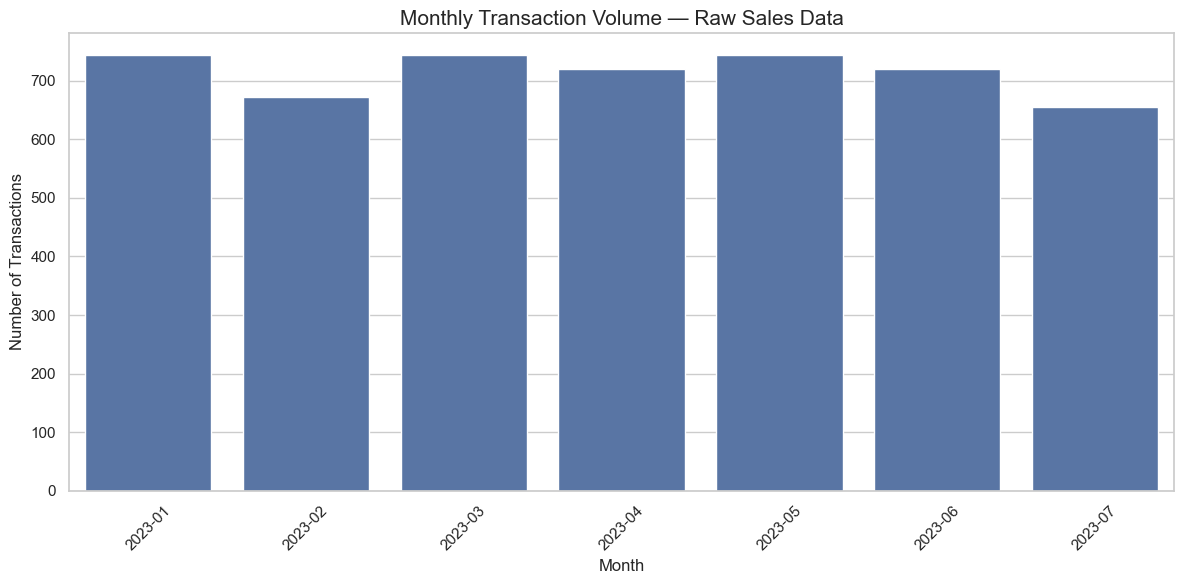

In [91]:

# ==========================================
# GRAPH: MONTHLY TRANSACTION VOLUME
# USING RAW SALES DATA
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure TransactionDate is in datetime format
sales["TransactionDate"] = pd.to_datetime(
    sales["TransactionDate"],
    errors="coerce"
)

# Extract month and calculate unique transactions
monthly_transactions = (
    sales.dropna(subset=["TransactionDate"])
    .assign(
        Month=lambda df: df["TransactionDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month")["TransactionID"]
    .nunique()
    .reset_index(name="Total_Transactions")
    .sort_values("Month")
)

# Display monthly transaction counts
display(monthly_transactions)

# Create graph
plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_transactions,
    x="Month",
    y="Total_Transactions"
)

plt.title("Monthly Transaction Volume — Raw Sales Data", fontsize=15)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Work on copies so the original datasets remain unchanged
sales_df = clean_sales.copy()
products_df = clean_products.copy()
customers_df = clean_customers.copy()

# Convert numeric columns safely
for col in ["QuantityPurchased", "Revenue", "UnitPrice"]:
    if col in sales_df.columns:
        sales_df[col] = pd.to_numeric(sales_df[col], errors="coerce")

for col in ["StockLevel", "CatalogPrice"]:
    if col in products_df.columns:
        products_df[col] = pd.to_numeric(products_df[col], errors="coerce")

# Parse dates
sales_df["TransactionDate"] = pd.to_datetime(
    sales_df["TransactionDate"], errors="coerce"
)

# Check the available columns
print("Sales columns:", sales_df.columns.tolist())
print("Product columns:", products_df.columns.tolist())
print("Customer columns:", customers_df.columns.tolist())

print("\nSales rows:", len(sales_df))
print("Products:", len(products_df))
print("Customers:", len(customers_df))

Sales columns: ['TransactionID', 'CustomerID', 'ProductID', 'QuantityPurchased', 'TransactionDate', 'RecordedPrice', 'UnitPrice', 'PriceCorrected', 'RawRevenue', 'Revenue']
Product columns: ['ProductID', 'ProductName', 'Category', 'StockLevel', 'CatalogPrice']
Customer columns: ['CustomerID', 'Age', 'AgeGroup', 'Gender', 'Location', 'JoinDate']

Sales rows: 5000
Products: 200
Customers: 1000


In [93]:
clean_customers.head()

,CustomerID,Age,AgeGroup,Gender,Location,JoinDate
0,1,63.0,55-64,Other,East,2020-01-01
1,2,63.0,55-64,Male,North,2020-01-02
2,3,34.0,25-34,Other,North,2020-01-03
3,4,19.0,18-24,Other,Unknown,2020-01-04
4,5,57.0,55-64,Male,North,2020-01-05


## Sales Volume by Product Category

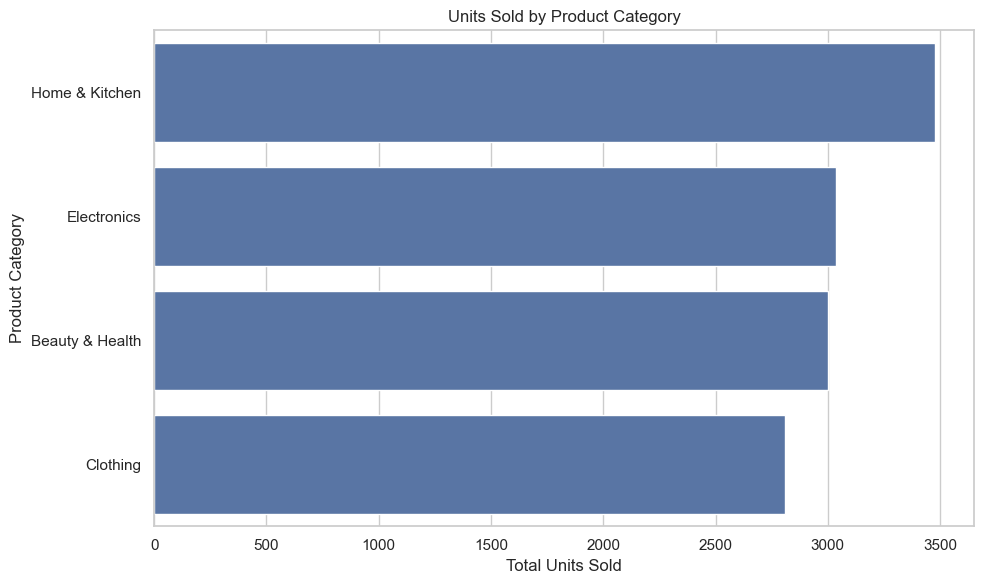

In [94]:
category_units = (
    sales_df
    .merge(
        products_df[["ProductID", "Category"]],
        on="ProductID",
        how="left"
    )
    .groupby("Category", as_index=False)["QuantityPurchased"]
    .sum()
    .sort_values("QuantityPurchased", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_units,
    x="QuantityPurchased",
    y="Category"
)

plt.title("Units Sold by Product Category")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

## Inventory Levels Across Categories

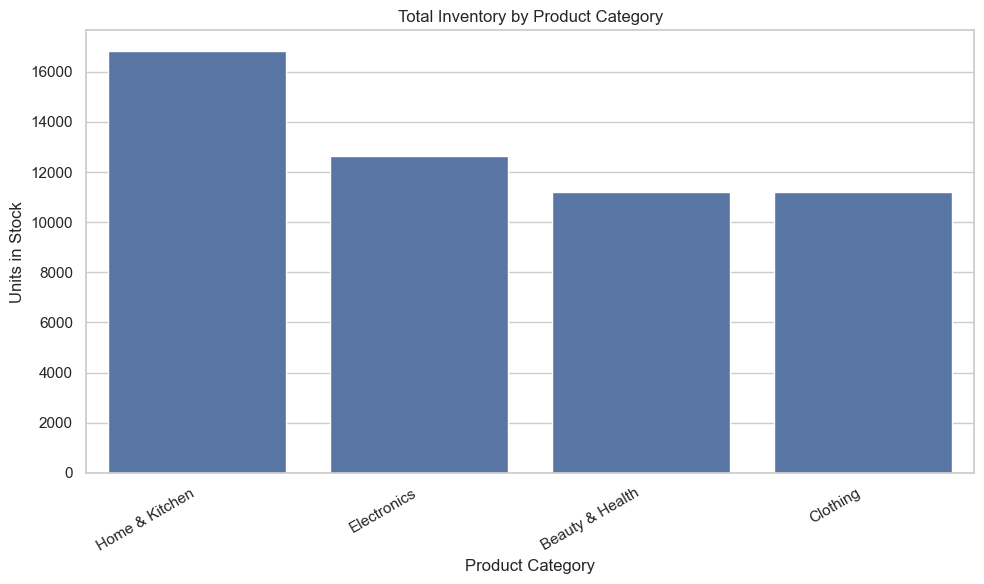

In [95]:
inventory_category = (
    products_df
    .groupby("Category", as_index=False)["StockLevel"]
    .sum()
    .sort_values("StockLevel", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=inventory_category,
    x="Category",
    y="StockLevel"
)

plt.title("Total Inventory by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Units in Stock")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Product Price Distribution

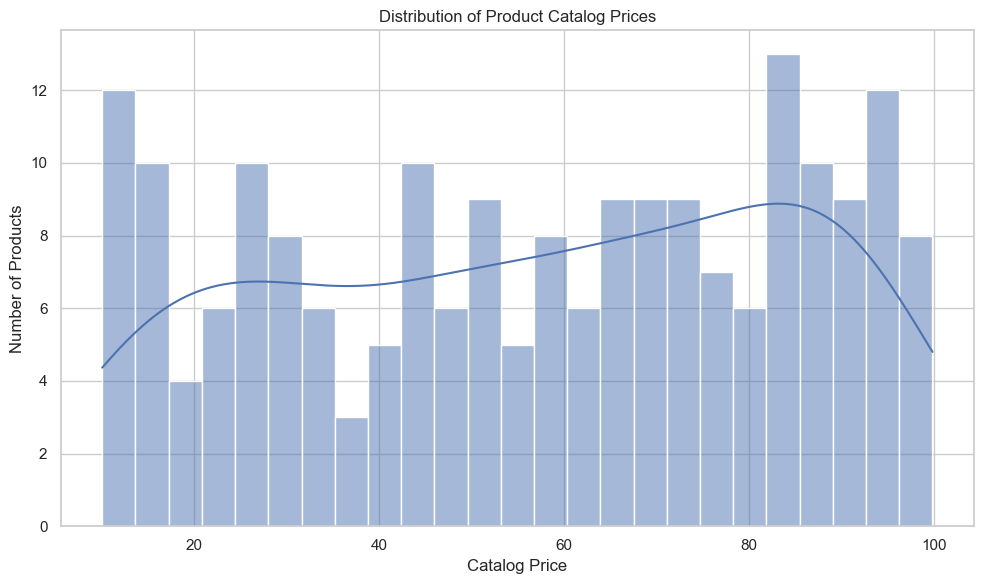

In [96]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=products_df,
    x="CatalogPrice",
    bins=25,
    kde=True
)

plt.title("Distribution of Product Catalog Prices")
plt.xlabel("Catalog Price")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

## Revenue Distribution Across Transactions

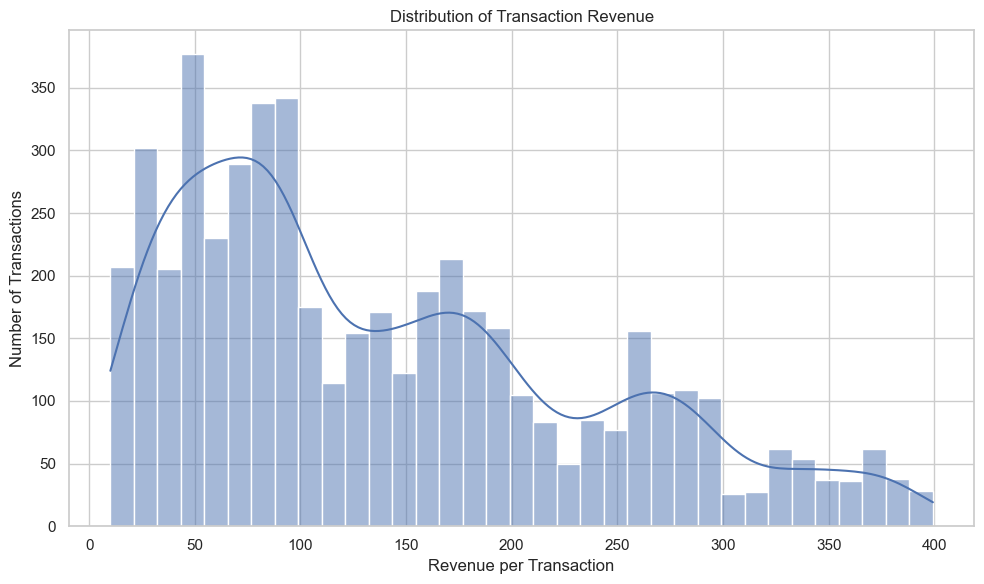

In [97]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=sales_df,
    x="Revenue",
    bins=35,
    kde=True
)

plt.title("Distribution of Transaction Revenue")
plt.xlabel("Revenue per Transaction")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## Transaction Quantity Distribution

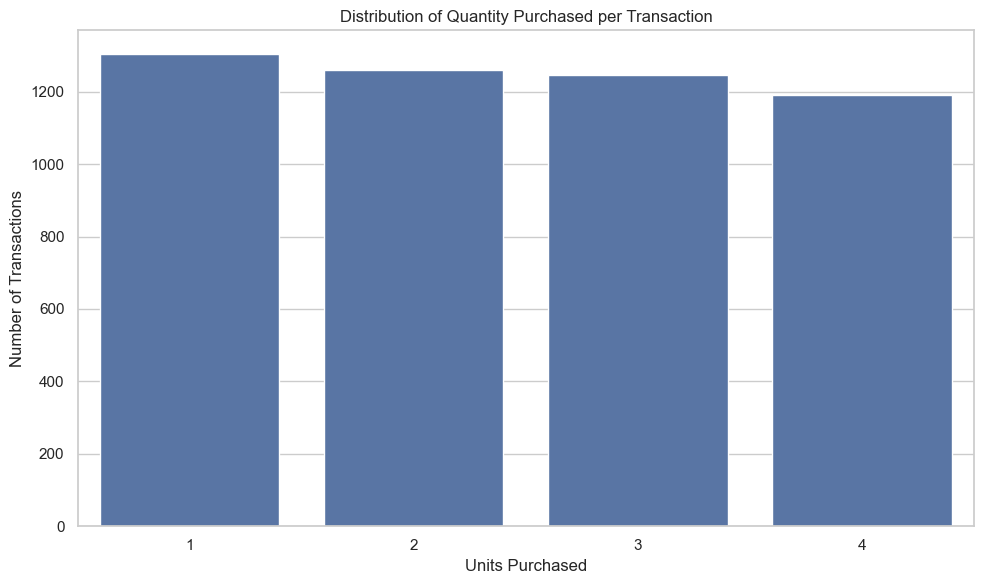

In [98]:
quantity_distribution = (
    sales_df["QuantityPurchased"]
    .value_counts()
    .sort_index()
    .reset_index()
)

quantity_distribution.columns = ["Quantity", "TransactionCount"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=quantity_distribution,
    x="Quantity",
    y="TransactionCount"
)

plt.title("Distribution of Quantity Purchased per Transaction")
plt.xlabel("Units Purchased")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## Revenue by Day of the Week

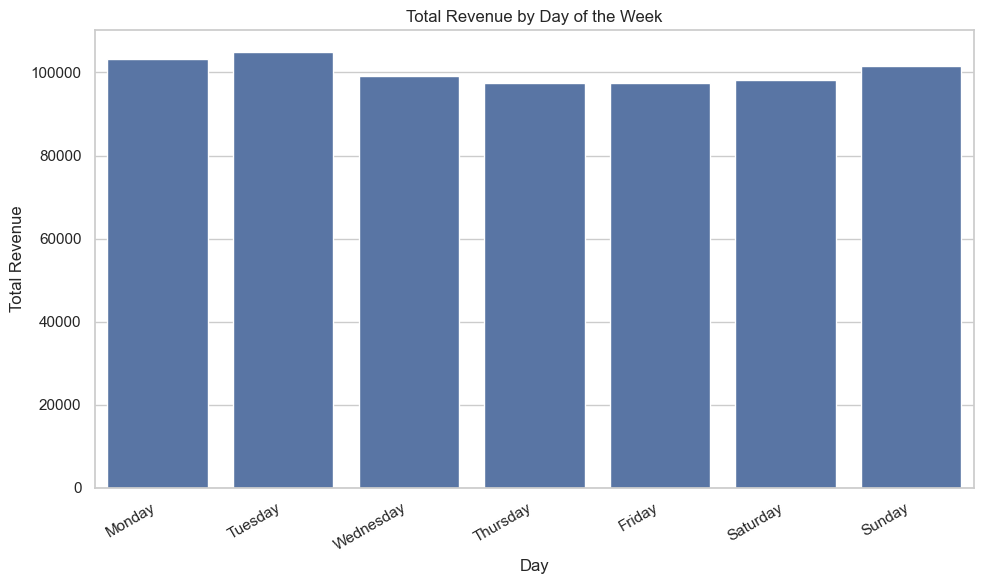

In [99]:
sales_df["DayOfWeek"] = sales_df["TransactionDate"].dt.dayofweek

day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_revenue = (
    sales_df
    .groupby("DayOfWeek", as_index=False)["Revenue"]
    .sum()
)

weekday_revenue["Day"] = weekday_revenue["DayOfWeek"].map(day_names)

weekday_revenue = weekday_revenue.sort_values("DayOfWeek")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weekday_revenue,
    x="Day",
    y="Revenue"
)

plt.title("Total Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Average Transaction Revenue by Day

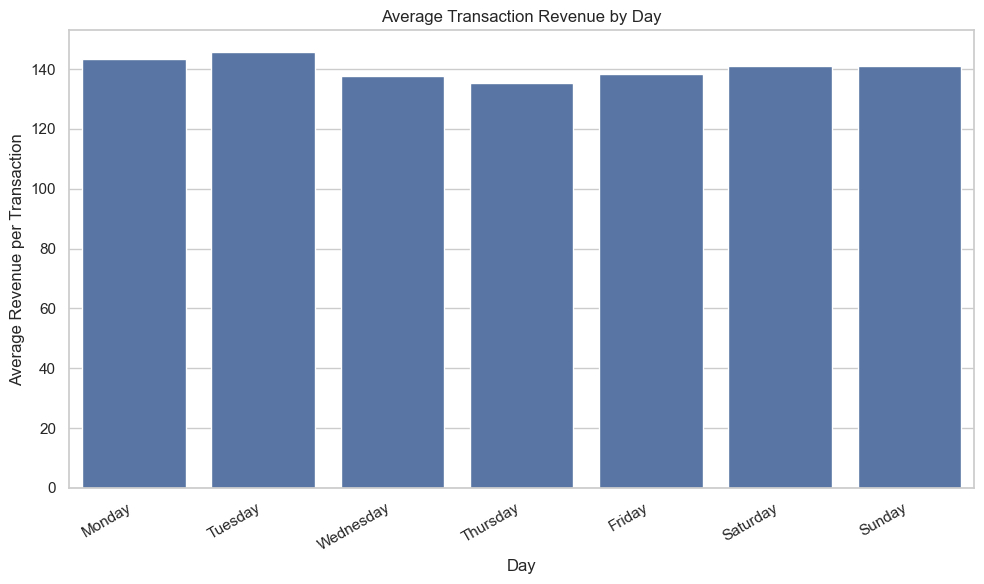

In [100]:
weekday_average = (
    sales_df
    .groupby("DayOfWeek", as_index=False)
    .agg(
        AverageRevenue=("Revenue", "mean"),
        TransactionCount=("TransactionID", "nunique")
    )
)

weekday_average["Day"] = weekday_average["DayOfWeek"].map(day_names)
weekday_average = weekday_average.sort_values("DayOfWeek")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weekday_average,
    x="Day",
    y="AverageRevenue"
)

plt.title("Average Transaction Revenue by Day")
plt.xlabel("Day")
plt.ylabel("Average Revenue per Transaction")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Average Product Revenue

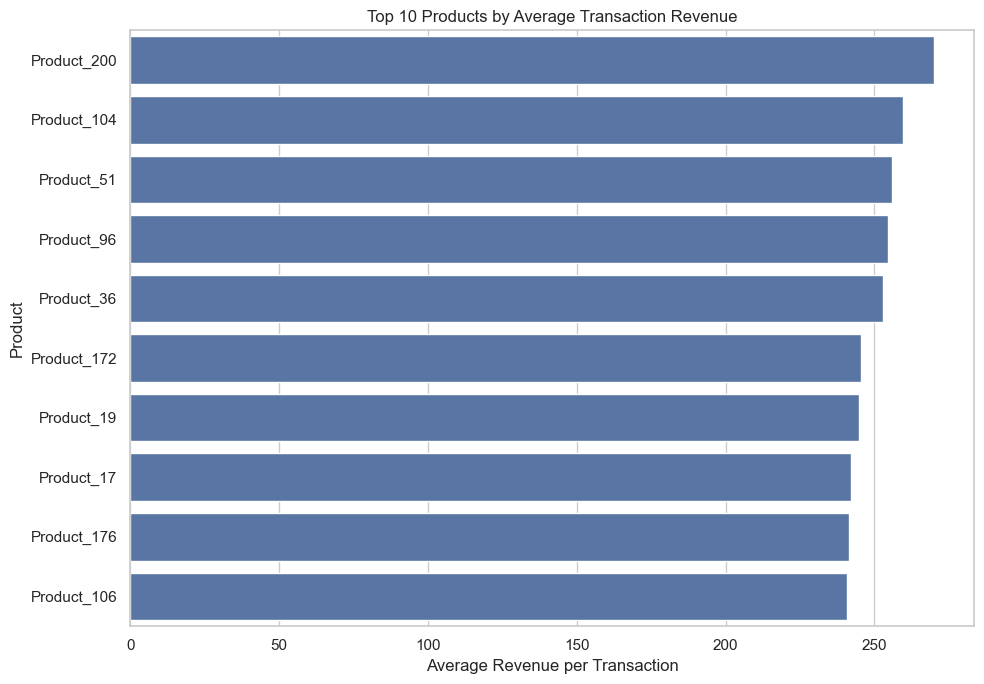

In [101]:
product_average = (
    sales_df
    .groupby("ProductID", as_index=False)
    .agg(
        AverageRevenue=("Revenue", "mean"),
        TransactionCount=("TransactionID", "nunique")
    )
    .merge(
        products_df[["ProductID", "ProductName"]],
        on="ProductID",
        how="left"
    )
)

top_average_products = (
    product_average[product_average["TransactionCount"] >= 2]
    .nlargest(10, "AverageRevenue")
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_average_products,
    x="AverageRevenue",
    y="ProductName"
)

plt.title("Top 10 Products by Average Transaction Revenue")
plt.xlabel("Average Revenue per Transaction")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## Revenue per Unit by Product Category

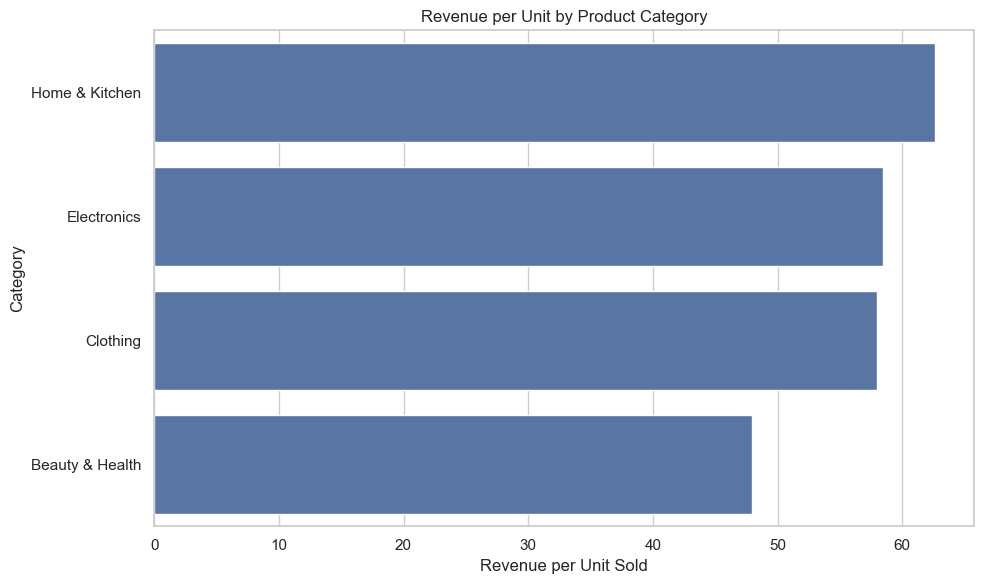

In [102]:
category_unit_economics = (
    sales_df
    .merge(
        products_df[["ProductID", "Category"]],
        on="ProductID",
        how="left"
    )
    .groupby("Category", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("QuantityPurchased", "sum")
    )
)

category_unit_economics["RevenuePerUnit"] = (
    category_unit_economics["TotalRevenue"]
    / category_unit_economics["UnitsSold"].replace(0, np.nan)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_unit_economics.sort_values(
        "RevenuePerUnit", ascending=False
    ),
    x="RevenuePerUnit",
    y="Category"
)

plt.title("Revenue per Unit by Product Category")
plt.xlabel("Revenue per Unit Sold")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Customer Revenue Distribution

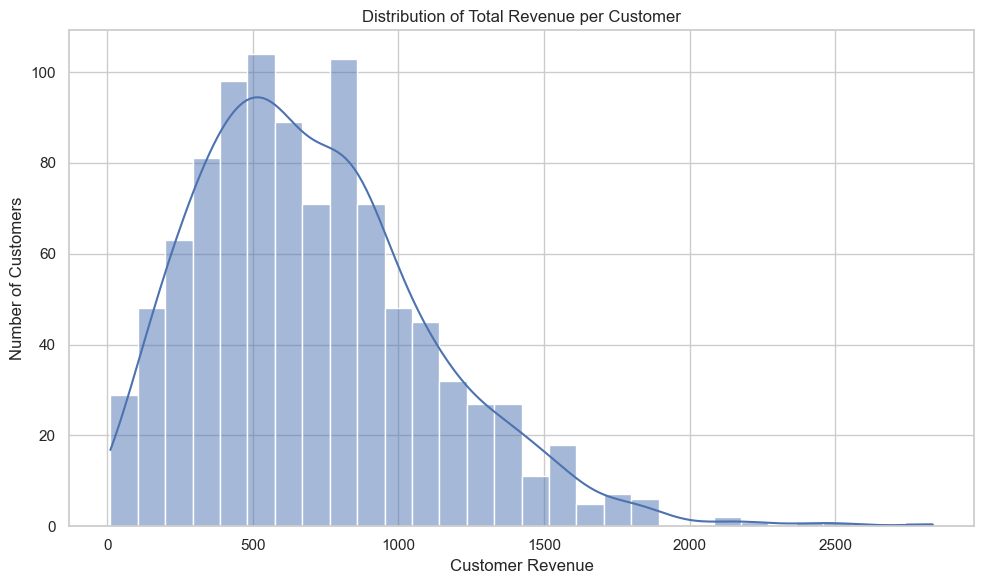

In [103]:
customer_revenue = (
    sales_df
    .groupby("CustomerID", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalTransactions=("TransactionID", "nunique")
    )
)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=customer_revenue,
    x="TotalRevenue",
    bins=30,
    kde=True
)

plt.title("Distribution of Total Revenue per Customer")
plt.xlabel("Customer Revenue")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Insights from Graph
1. Revenue is right-skewed, with most customers being low spenders
2. A small group of high-value customers sits in the long tail
3. The mean overstates what a typical customer spends


## Customer Transaction Frequency Distribution

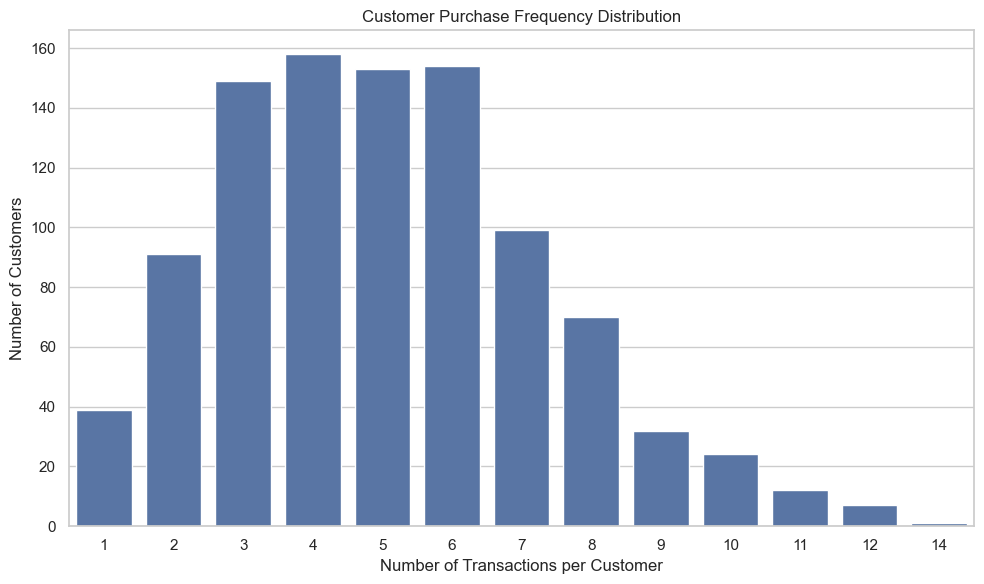

In [104]:
customer_frequency = (
    sales_df
    .groupby("CustomerID")["TransactionID"]
    .nunique()
    .value_counts()
    .sort_index()
    .reset_index()
)

customer_frequency.columns = [
    "NumberOfTransactions",
    "NumberOfCustomers"
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_frequency,
    x="NumberOfTransactions",
    y="NumberOfCustomers"
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Transactions per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

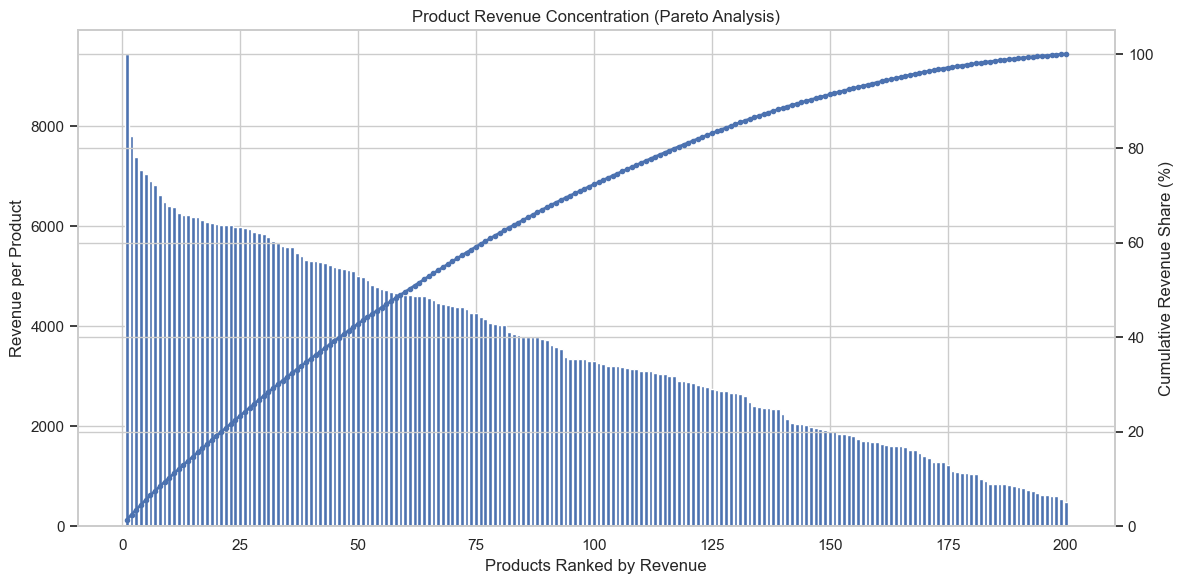

Products accounting for approximately 80% of revenue: 118


In [105]:
product_revenue = (
    sales_df
    .groupby("ProductID", as_index=False)["Revenue"]
    .sum()
    .merge(
        products_df[["ProductID", "ProductName"]],
        on="ProductID",
        how="left"
    )
    .sort_values("Revenue", ascending=False)
)

total_revenue = product_revenue["Revenue"].sum()

if total_revenue > 0:
    product_revenue["CumulativeRevenueShare"] = (
        product_revenue["Revenue"].cumsum() / total_revenue * 100
    )

    product_revenue["ProductRank"] = range(
        1, len(product_revenue) + 1
    )

    fig, ax1 = plt.subplots(figsize=(12, 6))

    ax1.bar(
        product_revenue["ProductRank"],
        product_revenue["Revenue"]
    )

    ax1.set_xlabel("Products Ranked by Revenue")
    ax1.set_ylabel("Revenue per Product")
    ax1.set_title("Product Revenue Concentration (Pareto Analysis)")

    ax2 = ax1.twinx()

    ax2.plot(
        product_revenue["ProductRank"],
        product_revenue["CumulativeRevenueShare"],
        marker=".",
        linewidth=2
    )

    ax2.set_ylabel("Cumulative Revenue Share (%)")
    ax2.set_ylim(0, 105)

    plt.tight_layout()
    plt.show()

    # How many products generate 80% of revenue?
    products_for_80_percent = (
        product_revenue["CumulativeRevenueShare"] < 80
    ).sum() + 1

    print(
        f"Products accounting for approximately 80% of revenue: "
        f"{products_for_80_percent}"
    )
else:
    print("Revenue total is zero or negative; Pareto analysis is unavailable.")

## Insights
- Revenue Concentration: Approximately 80% of total product revenue is generated by 103 out of 200 products, indicating that revenue is distributed across a relatively small portion of the product portfolio.
- Top-Performing Products: A small number of products generate significantly higher revenue than the rest, making them important contributors to overall sales performance.
- Long-Tail Distribution: Many products contribute relatively little revenue individually, suggesting that product performance varies considerably across the catalogue.
- Business Recommendation: Prioritize inventory availability for high-revenue products while reviewing the profitability and demand of lower-performing products to identify opportunities for improvement.

# RFM 

In [107]:
# Validate RFM customer segmentation
# Define the final RFM DataFrame
rfm = rfm_basic.copy()

# Add RFM scores and customer segments if they exist
# in the final RFM workflow
print("Number of customers in RFM:", rfm["CustomerID"].nunique())

print("\nCustomer count by segment:")
display(
    rfm["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Customer_Count")
)

print("\nRevenue reconciliation:")
print("Corrected sales revenue:", round(clean_sales["Revenue"].sum(), 2))
print("RFM monetary total:", round(rfm["Monetary"].sum(), 2))

print(
    "Revenue totals match:",
    np.isclose(
        clean_sales["Revenue"].sum(),
        rfm["Monetary"].sum()
    )
)

Number of customers in RFM: 989

Customer count by segment:


,Customer_Segment,Customer_Count
0,Other Customers,309
1,High-Value Customers,263
2,Previously Frequent Customers,185
3,Loyal / Active Customers,157
4,Recent One-Time Customers,75



Revenue reconciliation:
Corrected sales revenue: 702003.62
RFM monetary total: 702003.62
Revenue totals match: True


In [108]:

# ==========================================
# RFM ANALYSIS: DATA PREPARATION AND SCORING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Work with cleaned data
rfm_data = clean_sales.copy()

# 2. Validate required columns
required_columns = [
    "CustomerID",
    "TransactionID",
    "TransactionDate",
    "Revenue"
]

missing_columns = [
    col for col in required_columns
    if col not in rfm_data.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# 3. Convert columns to appropriate data types
rfm_data["TransactionDate"] = pd.to_datetime(
    rfm_data["TransactionDate"],
    errors="coerce"
)

rfm_data["Revenue"] = pd.to_numeric(
    rfm_data["Revenue"],
    errors="coerce"
)

# 4. Remove rows with missing essential values
rfm_data = rfm_data.dropna(
    subset=[
        "CustomerID",
        "TransactionID",
        "TransactionDate",
        "Revenue"
    ]
)

# 5. Keep valid revenue records
rfm_data = rfm_data[rfm_data["Revenue"] >= 0].copy()

if rfm_data.empty:
    raise ValueError("No valid sales records remain for RFM analysis.")

# 6. Set reference date to one day after the last transaction
reference_date = (
    rfm_data["TransactionDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# 7. Calculate RFM metrics
rfm = (
    rfm_data.groupby("CustomerID")
    .agg(
        Recency=(
            "TransactionDate",
            lambda x: (reference_date - x.max().normalize()).days
        ),
        Frequency=("TransactionID", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# 8. Create RFM scores from 1 to 5
# Rank first to handle duplicate values safely.

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first", ascending=True),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# 9. Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm["RFM_Total"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# 10. Create interpretable customer segments
def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3 and m >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "Recent Customers"
    elif r <= 2 and f >= 3 and m >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2:
        return "Hibernating"
    elif m >= 4:
        return "High Spending"
    else:
        return "Potential Loyalists"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# 11. Display results
print("Reference date:", reference_date.date())
print("Customers included in RFM:", rfm["CustomerID"].nunique())

display(rfm.head(10))

# 12. Save the RFM table
rfm.to_csv("retail_rfm_analysis.csv", index=False)

print("RFM analysis saved as retail_rfm_analysis.csv")


Reference date: 2023-07-29
Customers included in RFM: 989


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Segment
0,1,4,9,1188.04,5,5,5,555,15,Champions
1,2,85,6,895.57,1,3,4,134,8,At Risk
2,3,88,4,513.03,1,2,2,122,5,Hibernating
3,4,134,2,174.08,1,1,1,111,3,Hibernating
4,5,150,5,582.73,1,3,3,133,7,At Risk
5,6,154,1,80.70,1,1,1,111,3,Hibernating
6,7,15,7,1383.86,4,4,5,445,13,Champions
7,8,27,7,1297.25,3,4,5,345,12,Loyal Customers
8,9,104,3,649.93,1,1,3,113,5,Hibernating
9,10,56,6,377.90,2,3,2,232,7,Potential Loyalists


RFM analysis saved as retail_rfm_analysis.csv


,Segment,CustomerCount
0,Hibernating,224
1,Loyal Customers,196
2,Champions,175
3,Potential Loyalists,144
4,At Risk,139
5,Recent Customers,105
6,High Spending,6


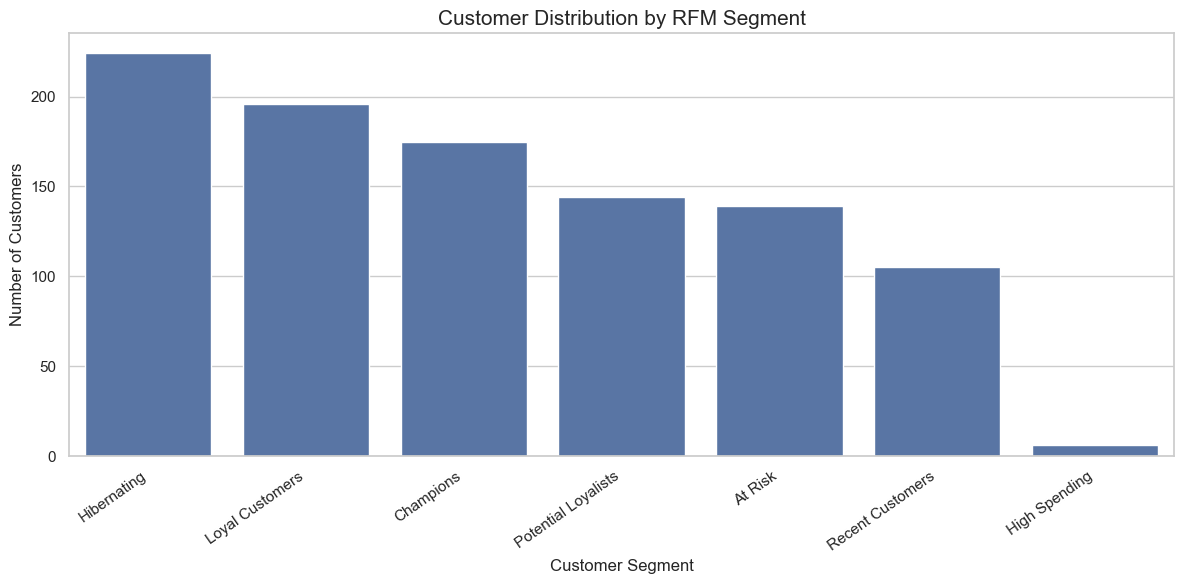

In [109]:

# ==========================================
# GRAPH 1: CUSTOMER COUNT BY RFM SEGMENT
# ==========================================

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)

display(segment_counts)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_counts,
    x="Segment",
    y="CustomerCount"
)

plt.title("Customer Distribution by RFM Segment", fontsize=15)
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



,Segment,TotalRevenue,CustomerCount,AverageRevenue,RevenueSharePct
1,Champions,209143.09,175,1195.10,29.79
4,Loyal Customers,169766.07,196,866.15,24.18
0,At Risk,129847.84,139,934.16,18.50
2,Hibernating,87819.33,224,392.05,12.51
5,Potential Loyalists,58194.61,144,404.13,8.29
6,Recent Customers,42119.58,105,401.14,6.00
3,High Spending,5113.10,6,852.18,0.73


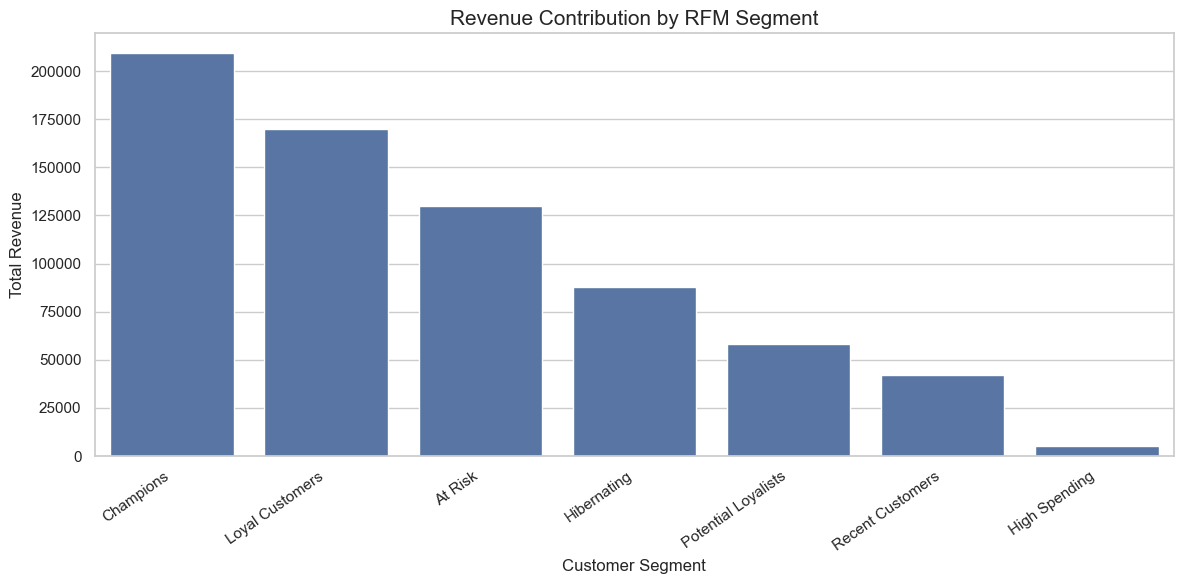

In [110]:
# ==========================================
# GRAPH 2: REVENUE CONTRIBUTION BY SEGMENT
# ==========================================

segment_revenue = (
    rfm.groupby("Segment", as_index=False)
    .agg(
        TotalRevenue=("Monetary", "sum"),
        CustomerCount=("CustomerID", "nunique"),
        AverageRevenue=("Monetary", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

segment_revenue["RevenueSharePct"] = (
    segment_revenue["TotalRevenue"]
    / segment_revenue["TotalRevenue"].sum()
    * 100
)

display(segment_revenue.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_revenue,
    x="Segment",
    y="TotalRevenue"
)

plt.title("Revenue Contribution by RFM Segment", fontsize=15)
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


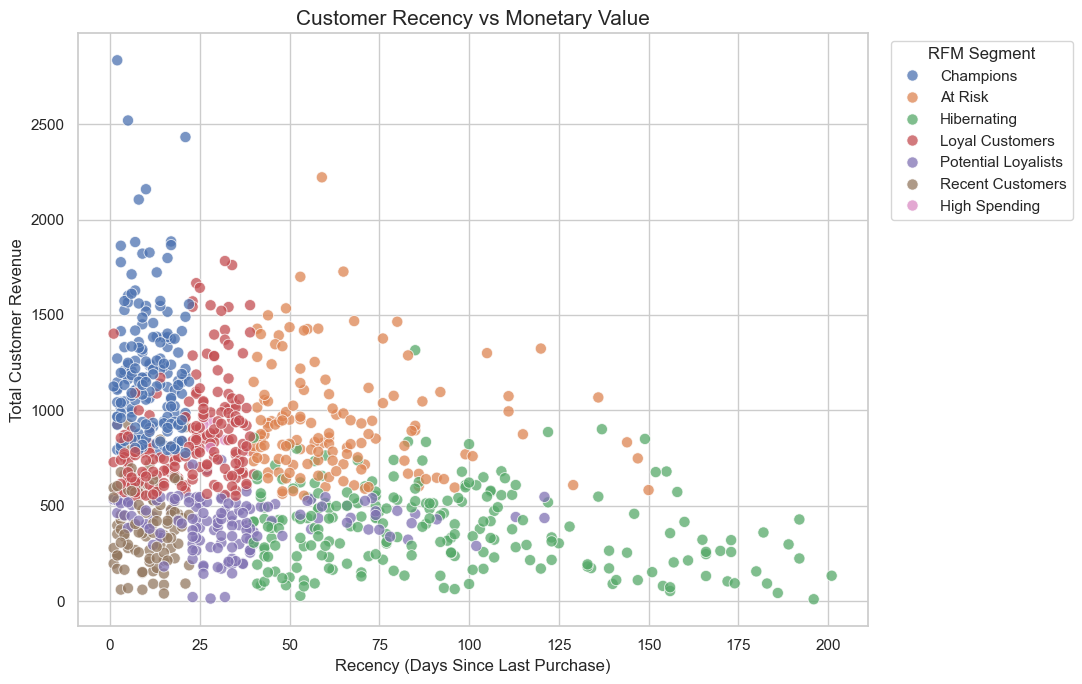

In [111]:
# ==========================================
# GRAPH 3: RECENCY VS MONETARY VALUE
# ==========================================

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Segment",
    alpha=0.75,
    s=65
)

plt.title("Customer Recency vs Monetary Value", fontsize=15)
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Customer Revenue")
plt.legend(
    title="RFM Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

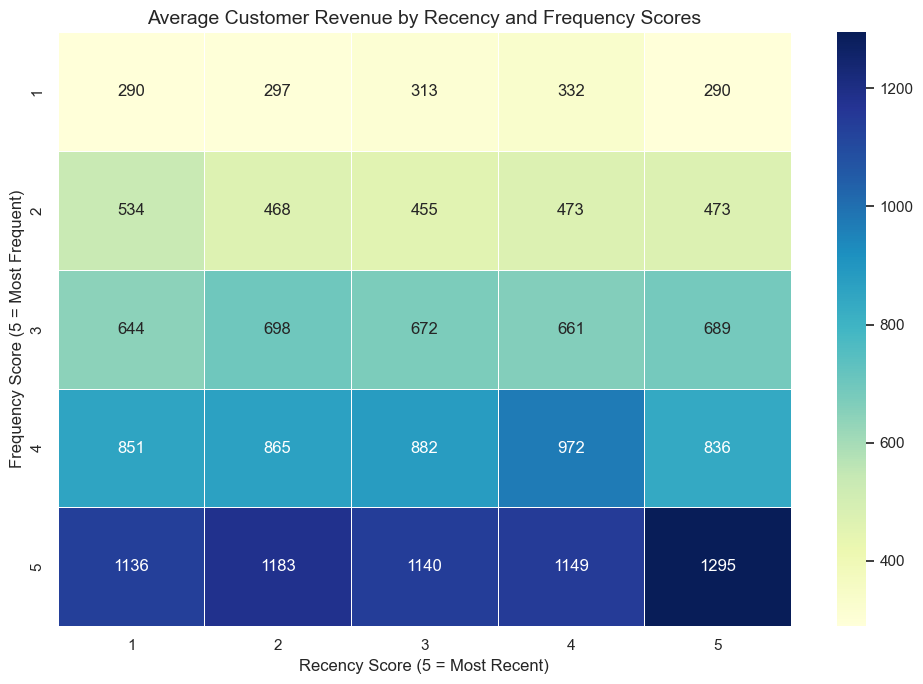

In [112]:

# ==========================================
# GRAPH 4: RFM SCORE HEATMAP
# ==========================================

rfm_heatmap = rfm.pivot_table(
    index="F_Score",
    columns="R_Score",
    values="Monetary",
    aggfunc="mean"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    rfm_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Average Customer Revenue by Recency and Frequency Scores",
    fontsize=14
)
plt.xlabel("Recency Score (5 = Most Recent)")
plt.ylabel("Frequency Score (5 = Most Frequent)")
plt.tight_layout()
plt.show()




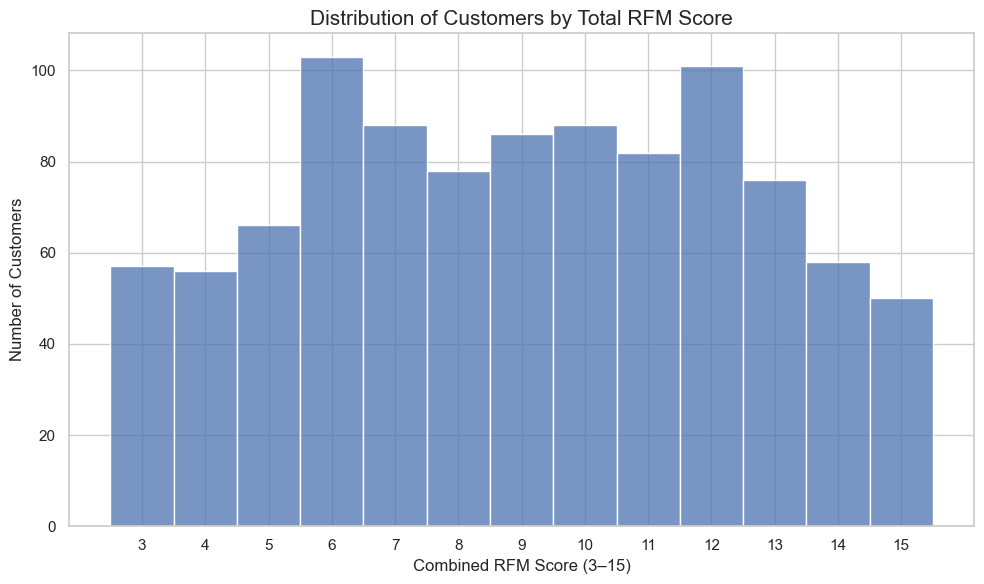

In [113]:

# ==========================================
# GRAPH 5: CUSTOMER COUNT BY RFM SCORE
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=rfm,
    x="RFM_Total",
    bins=np.arange(2.5, 15.5, 1),
    discrete=True
)

plt.title("Distribution of Customers by Total RFM Score", fontsize=15)
plt.xlabel("Combined RFM Score (3–15)")
plt.ylabel("Number of Customers")
plt.xticks(range(3, 16))
plt.tight_layout()
plt.show()

In [114]:
# ==========================================
# BONUS: RFM BUSINESS SUMMARY
# ==========================================

total_customers = rfm["CustomerID"].nunique()
total_revenue = rfm["Monetary"].sum()

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        Revenue=("Monetary", "sum"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .reset_index()
)

segment_summary["CustomerSharePct"] = (
    segment_summary["Customers"] / total_customers * 100
)

segment_summary["RevenueSharePct"] = (
    segment_summary["Revenue"] / total_revenue * 100
)

segment_summary = segment_summary.sort_values(
    "Revenue",
    ascending=False
)

display(segment_summary.round(2))

print(f"Customers analyzed: {total_customers:,}")
print(f"Total revenue analyzed: {total_revenue:,.2f}")

# Highest-revenue segment
top_segment = segment_summary.iloc[0]

print("\nHighest-revenue segment:", top_segment["Segment"])
print(f"Revenue contribution: {top_segment['RevenueSharePct']:.2f}%")
print(f"Customer contribution: {top_segment['CustomerSharePct']:.2f}%")


,Segment,Customers,Revenue,Average_Recency,Average_Frequency,Average_Monetary,CustomerSharePct,RevenueSharePct
1,Champions,175,209143.09,10.82,7.83,1195.10,17.69,29.79
4,Loyal Customers,196,169766.07,22.28,6.14,866.15,19.82,24.18
0,At Risk,139,129847.84,64.06,6.27,934.16,14.05,18.50
2,Hibernating,224,87819.33,91.61,2.76,392.05,22.65,12.51
5,Potential Loyalists,144,58194.61,35.50,4.15,404.13,14.56,8.29
6,Recent Customers,105,42119.58,10.68,3.01,401.14,10.62,6.00
3,High Spending,6,5113.10,29.50,3.67,852.18,0.61,0.73


Customers analyzed: 989
Total revenue analyzed: 702,003.62

Highest-revenue segment: Champions
Revenue contribution: 29.79%
Customer contribution: 17.69%


## 4. Customer Segment Analysis

Customers are categorized into behavioral segments using their RFM scores. Each segment represents a different customer profile and may require a different engagement strategy.

### Champions

Customers with high recency, frequency, and monetary scores. They have purchased relatively recently, transact frequently, and contribute substantial revenue.

**Recommended strategy:** Maintain engagement through loyalty benefits, personalized recommendations, and relevant product offers.

### Loyal Customers

Customers who demonstrate consistently favorable RFM scores and purchasing behavior.

**Recommended strategy:** Encourage continued engagement through loyalty programs, personalized communication, and cross-selling opportunities.

### Recent Customers

Customers who have purchased relatively recently but have lower frequency scores.

**Recommended strategy:** Encourage a second purchase through relevant recommendations and onboarding campaigns.

### At Risk

Customers with relatively low recency scores but favorable frequency and monetary scores. They have not purchased recently despite having previously demonstrated valuable purchasing behavior.

**Recommended strategy:** Evaluate targeted re-engagement campaigns and personalized offers.

### Hibernating Customers

Customers with relatively low recency, frequency, and monetary scores.

**Recommended strategy:** Evaluate low-cost reactivation campaigns and determine whether further engagement is commercially worthwhile.

### Potential Loyalists

Customers who have purchased relatively recently but have not yet demonstrated the frequency or monetary value associated with the strongest customer segments.

**Recommended strategy:** Encourage repeat purchases through personalized recommendations and relevant incentives.

### High Spending Customers

Customers whose monetary scores are high but who do not necessarily meet the criteria for Champions or Loyal Customers.

**Recommended strategy:** Monitor their purchasing activity and develop relevant retention strategies based on their individual behavior.

**Note:** These segments are rule-based classifications, not universally standardized customer categories. Their definitions depend on the scoring approach and business requirements. A customer's assigned segment should be interpreted alongside their underlying RFM metrics.

In [115]:

# ==========================================
# RFM: HIGH-VALUE CUSTOMERS
# ==========================================

high_value_customers = (
    rfm[
        rfm["Segment"].isin([
            "Champions",
            "Loyal Customers",
            "High Spending"
        ])
    ]
    .sort_values("Monetary", ascending=False)
)

print("TOP 10 HIGH-VALUE CUSTOMERS")

display(
    high_value_customers[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "RFM_Score",
            "Segment"
        ]
    ].head(10)
)


# ==========================================
# RFM: CUSTOMERS WHO MAY BE AT RISK
# ==========================================

at_risk_customers = (
    rfm[rfm["Segment"] == "At Risk"]
    .sort_values(
        ["Monetary", "Recency"],
        ascending=[False, False]
    )
)

print("TOP 10 AT-RISK CUSTOMERS BY HISTORICAL REVENUE")

display(
    at_risk_customers[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "RFM_Score",
            "Segment"
        ]
    ].head(10)
)


# ==========================================
# RFM: EXPORT RESULTS
# ==========================================

rfm.to_csv("retail_rfm_customer_segments.csv", index=False)

segment_summary.to_csv(
    "retail_rfm_segment_summary.csv",
    index=False
)

print("RFM customer segmentation exported successfully.")
print("Files created:")
print("- retail_rfm_customer_segments.csv")
print("- retail_rfm_segment_summary.csv")


TOP 10 HIGH-VALUE CUSTOMERS


,CustomerID,Recency,Frequency,Monetary,RFM_Score,Segment
924,936,2,12,2834.47,555,Champions
657,664,5,14,2519.04,555,Champions
663,670,21,12,2432.15,455,Champions
429,435,10,10,2158.98,555,Champions
946,958,8,12,2104.71,555,Champions
359,364,17,8,1885.40,455,Champions
402,407,7,8,1882.26,555,Champions
909,921,17,10,1866.29,455,Champions
72,75,3,11,1862.73,555,Champions
548,554,11,10,1827.24,455,Champions


TOP 10 AT-RISK CUSTOMERS BY HISTORICAL REVENUE


,CustomerID,Recency,Frequency,Monetary,RFM_Score,Segment
38,39,59,12,2221.29,255,At Risk
127,130,65,9,1727.31,255,At Risk
520,526,53,10,1700.26,255,At Risk
257,261,49,8,1534.88,255,At Risk
158,161,44,10,1498.36,255,At Risk
465,471,68,5,1468.28,235,At Risk
453,459,80,7,1464.73,155,At Risk
75,78,50,6,1435.84,245,At Risk
457,463,58,6,1428.51,245,At Risk
250,254,41,9,1427.97,255,At Risk


RFM customer segmentation exported successfully.
Files created:
- retail_rfm_customer_segments.csv
- retail_rfm_segment_summary.csv


## 5. Key Business Insights

The RFM analysis evaluates the distribution of customers across behavioral segments and measures each segment's contribution to overall revenue.

The following areas should be investigated using the calculated segment summary.

### 1. Customer Value Concentration

Compare customer share with revenue share across segments to identify groups that contribute disproportionately to total revenue.

**Business implication:** Segments contributing a substantial proportion of revenue may warrant additional retention attention.

### 2. Customer Retention Opportunities

Examine the size and historical revenue contribution of the At Risk segment.

**Business implication:** Customers with high historical revenue and long periods since their last purchase may be candidates for targeted re-engagement.

### 3. Repeat-Purchase Opportunities

Review the Recent Customers and Potential Loyalists segments to identify customers who may benefit from relevant recommendations or repeat-purchase incentives.

**Business implication:** Engagement strategies can be tailored to customers who have purchased recently but have not yet developed frequent purchasing behavior.

### 4. Prioritization of Marketing Efforts

Compare the number of customers, average monetary value, and total revenue contribution across segments.

**Business implication:** Marketing resources can be prioritized according to customer value, potential retention opportunities, and the expected cost of engagement.

### 5. Limitations

RFM analysis summarizes historical purchasing behavior and does not directly measure customer satisfaction, profitability, or future purchase probability.

The analysis is also limited by the date range and completeness of the available sales data. Customers without valid sales records are not represented in transaction-based RFM segments.

Consequently, the results should be used to support customer prioritization rather than as definitive predictions of future customer behavior.

## STATISTICAL ANALYSIS: CUSTOMER BEHAVIOUR

In [116]:
# ==========================================
# STATISTICAL ANALYSIS: CUSTOMER BEHAVIOUR
# ==========================================

from scipy.stats import pearsonr, spearmanr

# Aggregate sales data at customer level
customer_analysis = clean_sales.groupby("CustomerID").agg(
    Total_Transactions=("TransactionID", "nunique"),
    Total_Revenue=("Revenue", "sum")
).reset_index()

# Calculate correlation
pearson_corr, pearson_p = pearsonr(
    customer_analysis["Total_Transactions"],
    customer_analysis["Total_Revenue"]
)

spearman_corr, spearman_p = spearmanr(
    customer_analysis["Total_Transactions"],
    customer_analysis["Total_Revenue"]
)

print("CUSTOMER PURCHASE FREQUENCY VS REVENUE")
print("-" * 45)
print(f"Pearson Correlation: {pearson_corr:.3f}")
print(f"Pearson p-value: {pearson_p:.5f}")
print(f"Spearman Correlation: {spearman_corr:.3f}")
print(f"Spearman p-value: {spearman_p:.5f}")

CUSTOMER PURCHASE FREQUENCY VS REVENUE
---------------------------------------------
Pearson Correlation: 0.838
Pearson p-value: 0.00000
Spearman Correlation: 0.839
Spearman p-value: 0.00000


In [117]:

# ==========================================
# STATISTICAL ANALYSIS: SETUP
# ==========================================

import pandas as pd
import numpy as np
from scipy import stats

# Use the cleaned dataset
stats_data = clean_sales.copy()

stats_data["TransactionDate"] = pd.to_datetime(
    stats_data["TransactionDate"],
    errors="coerce"
)

stats_data["Revenue"] = pd.to_numeric(
    stats_data["Revenue"],
    errors="coerce"
)

stats_data = stats_data.dropna(
    subset=["CustomerID", "TransactionID", "TransactionDate", "Revenue"]
)

stats_data = stats_data[stats_data["Revenue"] >= 0].copy()

# One row per customer
customer_stats = (
    stats_data.groupby("CustomerID")
    .agg(
        Frequency=("TransactionID", "nunique"),
        Monetary=("Revenue", "sum"),
        LastPurchase=("TransactionDate", "max")
    )
    .reset_index()
)

customer_stats["CustomerType"] = np.where(
    customer_stats["Frequency"] == 1,
    "One-time",
    "Repeat"
)

print("Valid sales rows:", len(stats_data))
print("Customers analyzed:", customer_stats["CustomerID"].nunique())
print("One-time customers:", (customer_stats["CustomerType"] == "One-time").sum())
print("Repeat customers:", (customer_stats["CustomerType"] == "Repeat").sum())

display(customer_stats.head())


Valid sales rows: 5000
Customers analyzed: 989
One-time customers: 39
Repeat customers: 950


,CustomerID,Frequency,Monetary,LastPurchase,CustomerType
0,1,9,1188.04,2023-07-25,Repeat
1,2,6,895.57,2023-05-05,Repeat
2,3,4,513.03,2023-05-02,Repeat
3,4,2,174.08,2023-03-17,Repeat
4,5,5,582.73,2023-03-01,Repeat


## Test 1 — Is purchase frequency associated with revenue?
## Test used: Spearman correlation.

In [118]:

# ==========================================
# TEST 1: FREQUENCY VS REVENUE
# ==========================================

correlation, p_value = stats.spearmanr(
    customer_stats["Frequency"],
    customer_stats["Monetary"]
)

print("SPEARMAN CORRELATION TEST")
print("-" * 40)
print(f"Correlation coefficient: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Statistically significant association.")
else:
    print("Result: No statistically significant association.")

if abs(correlation) < 0.2:
    strength = "very weak"
elif abs(correlation) < 0.4:
    strength = "weak"
elif abs(correlation) < 0.6:
    strength = "moderate"
elif abs(correlation) < 0.8:
    strength = "strong"
else:
    strength = "very strong"

direction = "positive" if correlation > 0 else "negative"

print(f"Observed association: {strength} {direction}.")


SPEARMAN CORRELATION TEST
----------------------------------------
Correlation coefficient: 0.8387
P-value: 0.000000
Result: Statistically significant association.
Observed association: very strong positive.


## Interpretation

The Spearman correlation coefficient of **0.8387** indicates a very strong positive association between purchase frequency and customer revenue. Customers who make purchases more frequently tend to generate higher total revenue.

The p-value is below **0.001**, indicating a statistically significant association between purchase frequency and revenue.

## Business Implications

- Monitor purchase frequency alongside customer revenue to understand purchasing behaviour.
- Evaluate loyalty programs and targeted campaigns to encourage repeat purchases.
- Identify customers whose purchase frequency is declining and consider appropriate retention strategies.

## Conclusion

Purchase frequency is positively and significantly associated with customer revenue. However, this association does not prove that increasing purchase frequency alone will cause revenue to increase.

## Test 2 — Do repeat customers generate different revenue from one-time customers?
## Test used: Mann–Whitney U test.

In [119]:
# ==========================================
# TEST 2: ONE-TIME VS REPEAT CUSTOMERS
# ==========================================

one_time = customer_stats.loc[
    customer_stats["CustomerType"] == "One-time",
    "Monetary"
]

repeat = customer_stats.loc[
    customer_stats["CustomerType"] == "Repeat",
    "Monetary"
]

print("ONE-TIME VS REPEAT CUSTOMER REVENUE")
print("-" * 45)

print(f"One-time customers: {len(one_time)}")
print(f"Repeat customers: {len(repeat)}")

print(f"One-time median revenue: {one_time.median():.2f}")
print(f"Repeat median revenue: {repeat.median():.2f}")

if len(one_time) > 0 and len(repeat) > 0:
    u_statistic, p_value = stats.mannwhitneyu(
        one_time,
        repeat,
        alternative="two-sided"
    )

    print(f"Mann–Whitney U statistic: {u_statistic:.2f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: The revenue distributions differ significantly.")
    else:
        print("Result: No statistically significant difference detected.")
else:
    print("Insufficient data: Both groups must contain customers.")


ONE-TIME VS REPEAT CUSTOMER REVENUE
---------------------------------------------
One-time customers: 39
Repeat customers: 950
One-time median revenue: 104.54
Repeat median revenue: 672.96
Mann–Whitney U statistic: 1213.00
P-value: 0.000000
Result: The revenue distributions differ significantly.


### Business Interpretation, Implications & Conclusion

1. **Revenue Difference:** Repeat customers have a median revenue of **672.96**, compared with **104.54** for one-time customers, indicating substantially higher customer-level revenue.

2. **Statistical Significance:** The Mann–Whitney U test returned a statistic of **1,213** and a p-value below **0.001**, indicating a statistically significant difference between the revenue distributions of the two groups.

3. **Business Implications:** Focus on customer retention through loyalty programs, personalized offers, and targeted campaigns to encourage one-time customers to make repeat purchases.

4. **Conclusion:** Repeat customers represent an important revenue segment. Strengthening retention strategies may support revenue growth, although the results establish an association rather than causation.

## Test 3 — Does spending differ across purchase-frequency groups?
## Test used: Kruskal–Wallis test

In [120]:

# ==========================================
# TEST 3: REVENUE ACROSS FREQUENCY GROUPS
# ==========================================

customer_stats["FrequencyGroup"] = pd.cut(
    customer_stats["Frequency"],
    bins=[0, 1, 3, np.inf],
    labels=["One-time", "Occasional (2–3)", "Frequent (4+)"]
)

frequency_summary = (
    customer_stats.groupby(
        "FrequencyGroup",
        observed=False
    )
    .agg(
        Customers=("CustomerID", "nunique"),
        MedianRevenue=("Monetary", "median"),
        AverageRevenue=("Monetary", "mean")
    )
    .reset_index()
)

display(frequency_summary.round(2))

groups = [
    group["Monetary"].values
    for _, group in customer_stats.groupby(
        "FrequencyGroup",
        observed=True
    )
    if len(group) > 0
]

if len(groups) >= 2:
    h_statistic, p_value = stats.kruskal(*groups)

    print(f"Kruskal–Wallis H statistic: {h_statistic:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: At least one frequency group differs in its revenue distribution.")
        print("A post-hoc test is needed to identify which groups differ.")
    else:
        print("Result: No statistically significant group difference detected.")
else:
    print("Insufficient data to compare frequency groups.")


,FrequencyGroup,Customers,MedianRevenue,AverageRevenue
0,One-time,39,104.54,139.97
1,Occasional (2–3),240,342.72,364.58
2,Frequent (4+),710,811.88,857.81


Kruskal–Wallis H statistic: 439.5393
P-value: 0.000000
Result: At least one frequency group differs in its revenue distribution.
A post-hoc test is needed to identify which groups differ.


## Interpretation

The results show an upward pattern in customer revenue across purchase-frequency groups.

- **One-time customers (39):** Median revenue of 104.54.
- **Occasional customers (240):** Median revenue of 342.72.
- **Frequent customers (710):** Median revenue of 811.88.

The Kruskal–Wallis test produced an H statistic of **439.5393** and a p-value below **0.001**. This provides strong statistical evidence that at least one group's revenue distribution differs from the others.

The test does not identify which specific groups differ significantly. Pairwise post-hoc testing would be required to determine this.

## Business Implications

- **Encourage engagement:** Consider strategies to encourage occasional customers to make additional purchases.
- **Retain frequent customers:** Evaluate loyalty benefits and personalized offers for customers who purchase frequently.
- **Monitor customer segments:** Track customer counts, purchase frequency, and revenue to assess the effectiveness of retention initiatives.

## Conclusion

Customer revenue distributions differ significantly across the three purchase-frequency groups. Frequent customers also have the highest observed median revenue. These findings can inform customer engagement and retention strategies, but they do not establish causation.

## Overall Statistical Findings

The three statistical tests provide complementary insights into customer purchasing behaviour.

| Analysis | Key Finding | Business Relevance |
|---|---|---|
| Spearman Correlation | Purchase frequency has a very strong positive association with revenue (ρ = 0.8387, p < 0.001). | Monitor purchase frequency alongside revenue and evaluate retention strategies. |
| Mann–Whitney U Test | One-time and repeat customers have significantly different revenue distributions (U = 1,213, p < 0.001). | Investigate opportunities to encourage repeat purchases and retain valuable customers. |
| Kruskal–Wallis Test | Revenue distributions differ significantly across purchase-frequency groups (H = 439.5393, p < 0.001). | Compare customer segments when planning targeted engagement initiatives. |

### Overall Conclusion

The analysis indicates that purchase frequency is strongly associated with customer revenue and that revenue distributions differ significantly between customer groups. These findings support evaluating customer retention and repeat-purchase initiatives. However, the results demonstrate statistical associations and differences, not causal relationships.